<a href="https://colab.research.google.com/github/dherreraal/data_structures/blob/main/Clase_12/12_ED_AVL_Delete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árboles AVL: Eliminación, Rebalanceo en Cascada y Visualización Completa
### Universidad Nacional de Colombia
#### **Profesor:** David Alberto Herrera Alvarez
#### **Curso:** Estructuras de Datos
---


## Índice de Contenido
1. Introducción y Repaso: La Estructura AVL y el Reto Asimétrico de la Eliminación
2. Eliminación en Árboles Binarios de Búsqueda (BST) como Base Estructural
   - 2.1 Caso 1: Eliminación de Nodo Hoja (0 hijos)
   - 2.2 Caso 2: Eliminación de Nodo con un Solo Hijo (1 hijo)
   - 2.3 Caso 3: Eliminación de Nodo con Dos Hijos (Sucesor vs. Predecesor In-Order)
   - 2.4 Localización del Punto Inicial de Rebalanceo ($M$)
3. Mecánica de Rebalanceo tras la Eliminación: Casos de Desbalanceo y Factor de Balance
   - 3.1 Detección del Desbalance ($|BF| > 1$) en el Camino Ascendente
   - 3.2 Los Casos Estándar (LL, RR, LR, RL)
   - 3.3 El Caso Exclusivo de la Eliminación: Factor de Balance del Hijo Igual a Cero ($BF = 0$)
   - 3.4 Tabla Decisional Completa de Rebalanceo Post-Eliminación
4. La Cascada de Rotaciones: Por qué Inserción es $O(1)$ rotaciones pero Eliminación es $O(\log n)$
   - 4.1 La Dinámica de Alturas: Restauración vs. Contracción
   - 4.2 Análisis del Peor Caso de Propagación hacia la Raíz
   - 4.3 Complejidad Temporal y Espacial Formal
5. Demostración Interactiva en Java 1: Implementación del Algoritmo `AVLDelete`
6. El Modelo Visual de Galles (USFCA Visualizer Trace) y Visualizador en Consola
   - 6.1 Traza Gráfica Paso a Paso de una Secuencia de Borrado
   - 6.2 Demostración Interactiva en Java 2: Visualizador Jerárquico 2D en Consola
7. Implementación Completa "OnlineGDB": Árbol AVL Industrial en Java
   - 7.1 Arquitectura Genérica con Inserción, Eliminación, Búsqueda y Recorridos
   - 7.2 Demostración Interactiva en Java 3: Árbol AVL Robusto y Completo
8. Buenas Prácticas y Errores Frecuentes (*Pitfalls*) al Eliminar en AVL
9. Ejercicios Prácticos
10. Bibliografía y Referencias
---


## 1. Introducción y Repaso: La Estructura AVL y el Reto Asimétrico de la Eliminación

El árbol AVL (nombrado en honor a sus creadores soviéticos **Georgy Adelson-Velsky** y **Evgenii Landis**, 1962) es una estructura de datos de búsqueda auto-balanceable. En todo árbol AVL deben coexistir estrictamente dos invariantes:

1. **Invariante de Búsqueda Binaria (BST Invariant):** Para cada nodo $N$, todas las claves en su subárbol izquierdo son estrictamente menores que la clave de $N$, y todas las claves en su subárbol derecho son estrictamente mayores ($N.\text{left}.\text{key} < N.\text{key} < N.\text{right}.\text{key}$).
2. **Invariante de Altura AVL (AVL Balance Invariant):** Para cada nodo $N$, la diferencia absoluta entre la altura de su subárbol izquierdo y la de su subárbol derecho no puede exceder 1:
$$|\text{BalanceFactor}(N)| = |\text{height}(N.\text{left}) - \text{height}(N.\text{right})| \le 1$$

Vimos además que la inserción de una clave es una operación sumamente predecible: un nuevo nodo siempre ingresa como una hoja, incrementando la altura de su subárbol en a lo sumo $1$. Si se producía un desbalance en el camino ascendente, bastaba ejecutar **a lo sumo una rotación (simple o doble)** en el ancestro desbalanceado más profundo; dicha rotación restauraba la altura del subárbol a su valor original previo a la inserción, neutralizando cualquier perturbación para los ancestros superiores.

### La Asimetría Fundamental: ¿Por qué la Eliminación es más Compleja?
La operación de eliminación (`delete(key)`) rompe esta conveniente garantía por una razón estructural profunda:

* **La inserción aumenta la altura:** Al rotar, la altura del subárbol se reduce al valor que tenía antes de insertar, por lo que su padre ve la misma altura de siempre. El rebalanceo se detiene con $O(1)$ rotaciones.
* **La eliminación contrae la altura:** Al borrar un nodo, el subárbol donde residía pierde altura. Si se aplica una rotación para rebalancear un ancestro desbalanceado, dicha rotación **reduce aún más** (o en el mejor caso mantiene) la altura del subárbol reestructurado. Al encogerse el subárbol, el ancestro superior (abuelo o bisabuelo) percibe una pérdida de altura en uno de sus lados, lo que puede provocar un **nuevo desbalance**.
* **Consecuencia matemática:** La eliminación puede requerir rebalanceos repetidos en **cada nivel del árbol** a lo largo de todo el camino hacia la raíz. Mientras que la inserción tiene una cota superior de $1$ rotación ($O(1)$ rotaciones), la eliminación puede exigir hasta $O(\log n)$ rotaciones sucesivas.

Comprender la eliminación requiere dominar tres fases interconectadas:
1. **La desconexión estructural BST:** Eliminar el nodo lógicamente respetando el orden simétrico.
2. **La identificación del nodo pivote:** Saber con exactitud matemática en qué nodo inicia el ascenso.
3. **El algoritmo de rebalanceo ascendente:** Detectar factores de balance, distinguir el caso especial $BF = 0$ y ejecutar rotaciones en cascada.


## 2. Eliminación en Árboles Binarios de Búsqueda (BST) como Base Estructural

La eliminación en un árbol AVL se fundamenta en la eliminación estándar de un Árbol Binario de Búsqueda (BST), pero con una diferencia cardinal: en un BST puro el algoritmo finaliza tras desconectar el nodo; en un AVL, la desconexión es apenas el **disparador** de la fase de rebalanceo ascendente.

Recordemos los tres casos de eliminación de un nodo $Z$:

### 2.1 Caso 1: Eliminación de Nodo Hoja (0 Hijos)
* **Condición:** $Z.\text{left} == \text{null}$ y $Z.\text{right} == \text{null}$.
* **Acción:** Se desvincula la referencia de su padre ($P.\text{left} = \text{null}$ o $P.\text{right} = \text{null}$). El nodo $Z$ queda huérfano y es reclamado por el *Garbage Collector*.
* **Punto de Rebalanceo:** El nodo padre $P$ es el primer nodo cuya altura y factor de balance deben recalcularse.

### 2.2 Caso 2: Eliminación de Nodo con un Solo Hijo (1 Hijo)
* **Condición:** $Z$ tiene exactamente un hijo no nulo (ya sea izquierdo o derecho).
* **Acción:** El padre de $Z$ establece un "puente directo" con el único hijo de $Z$, sorteando a $Z$ ($P.\text{child} = Z.\text{singleChild}$).
* **Punto de Rebalanceo:** El nodo padre $P$ asume la nueva rama y desde allí comienza el ascenso.

### 2.3 Caso 3: Eliminación de Nodo con Dos Hijos (2 Hijos)
* **Condición:** $Z.\text{left} \neq \text{null}$ y $Z.\text{right} \neq \text{null}$.
* **Acción:** No se puede desconectar $Z$ directamente sin fragmentar el árbol en tres partes desconectadas. Por tanto:
  1. Se localiza su **Sucesor In-Order** ($S$), que es el nodo con la clave mínima en el subárbol derecho ($S = \text{findMin}(Z.\text{right})$). Alternativamente se puede usar el predecesor in-order (máximo del subárbol izquierdo).
  2. Se copia la clave (y datos asociados) de $S$ en el nodo $Z$ ($Z.\text{key} = S.\text{key}$). Ahora el invariante BST se cumple en esa posición.
  3. Se elimina físicamente el nodo $S$ del subárbol derecho ($Z.\text{right} = \text{delete}(Z.\text{right}, S.\text{key})$).
  4. **Propiedad crucial:** Dado que $S$ es el mínimo del subárbol derecho, **$S$ no puede tener hijo izquierdo** ($S.\text{left} == \text{null}$). Por lo tanto, la eliminación física de $S$ siempre cae en el **Caso 1** (si es hoja) o en el **Caso 2** (si tiene hijo derecho).

### 2.4 Localización del Punto Inicial de Rebalanceo ($M$)
En el pseudocódigo clásico de Daniel Kane (UCSD):
```text
AVLDelete(N):
    Delete(N)
    M <- Parent of node replacing N
    Rebalance(M)
```
El nodo $M$ corresponde al ancestro inmediato que sufrió el desacoplamiento físico de un hijo. En una implementación recursiva idiomática en Java, esto se traduce de forma natural en el retorno de la llamada recursiva: al desenrollarse la pila de llamadas, cada marco de función visita a los ancestros desde el punto de borrado hacia la raíz.

A continuación se ilustran gráficamente los tres casos de eliminación y la ubicación del nodo de rebalanceo:

<div align="center">
  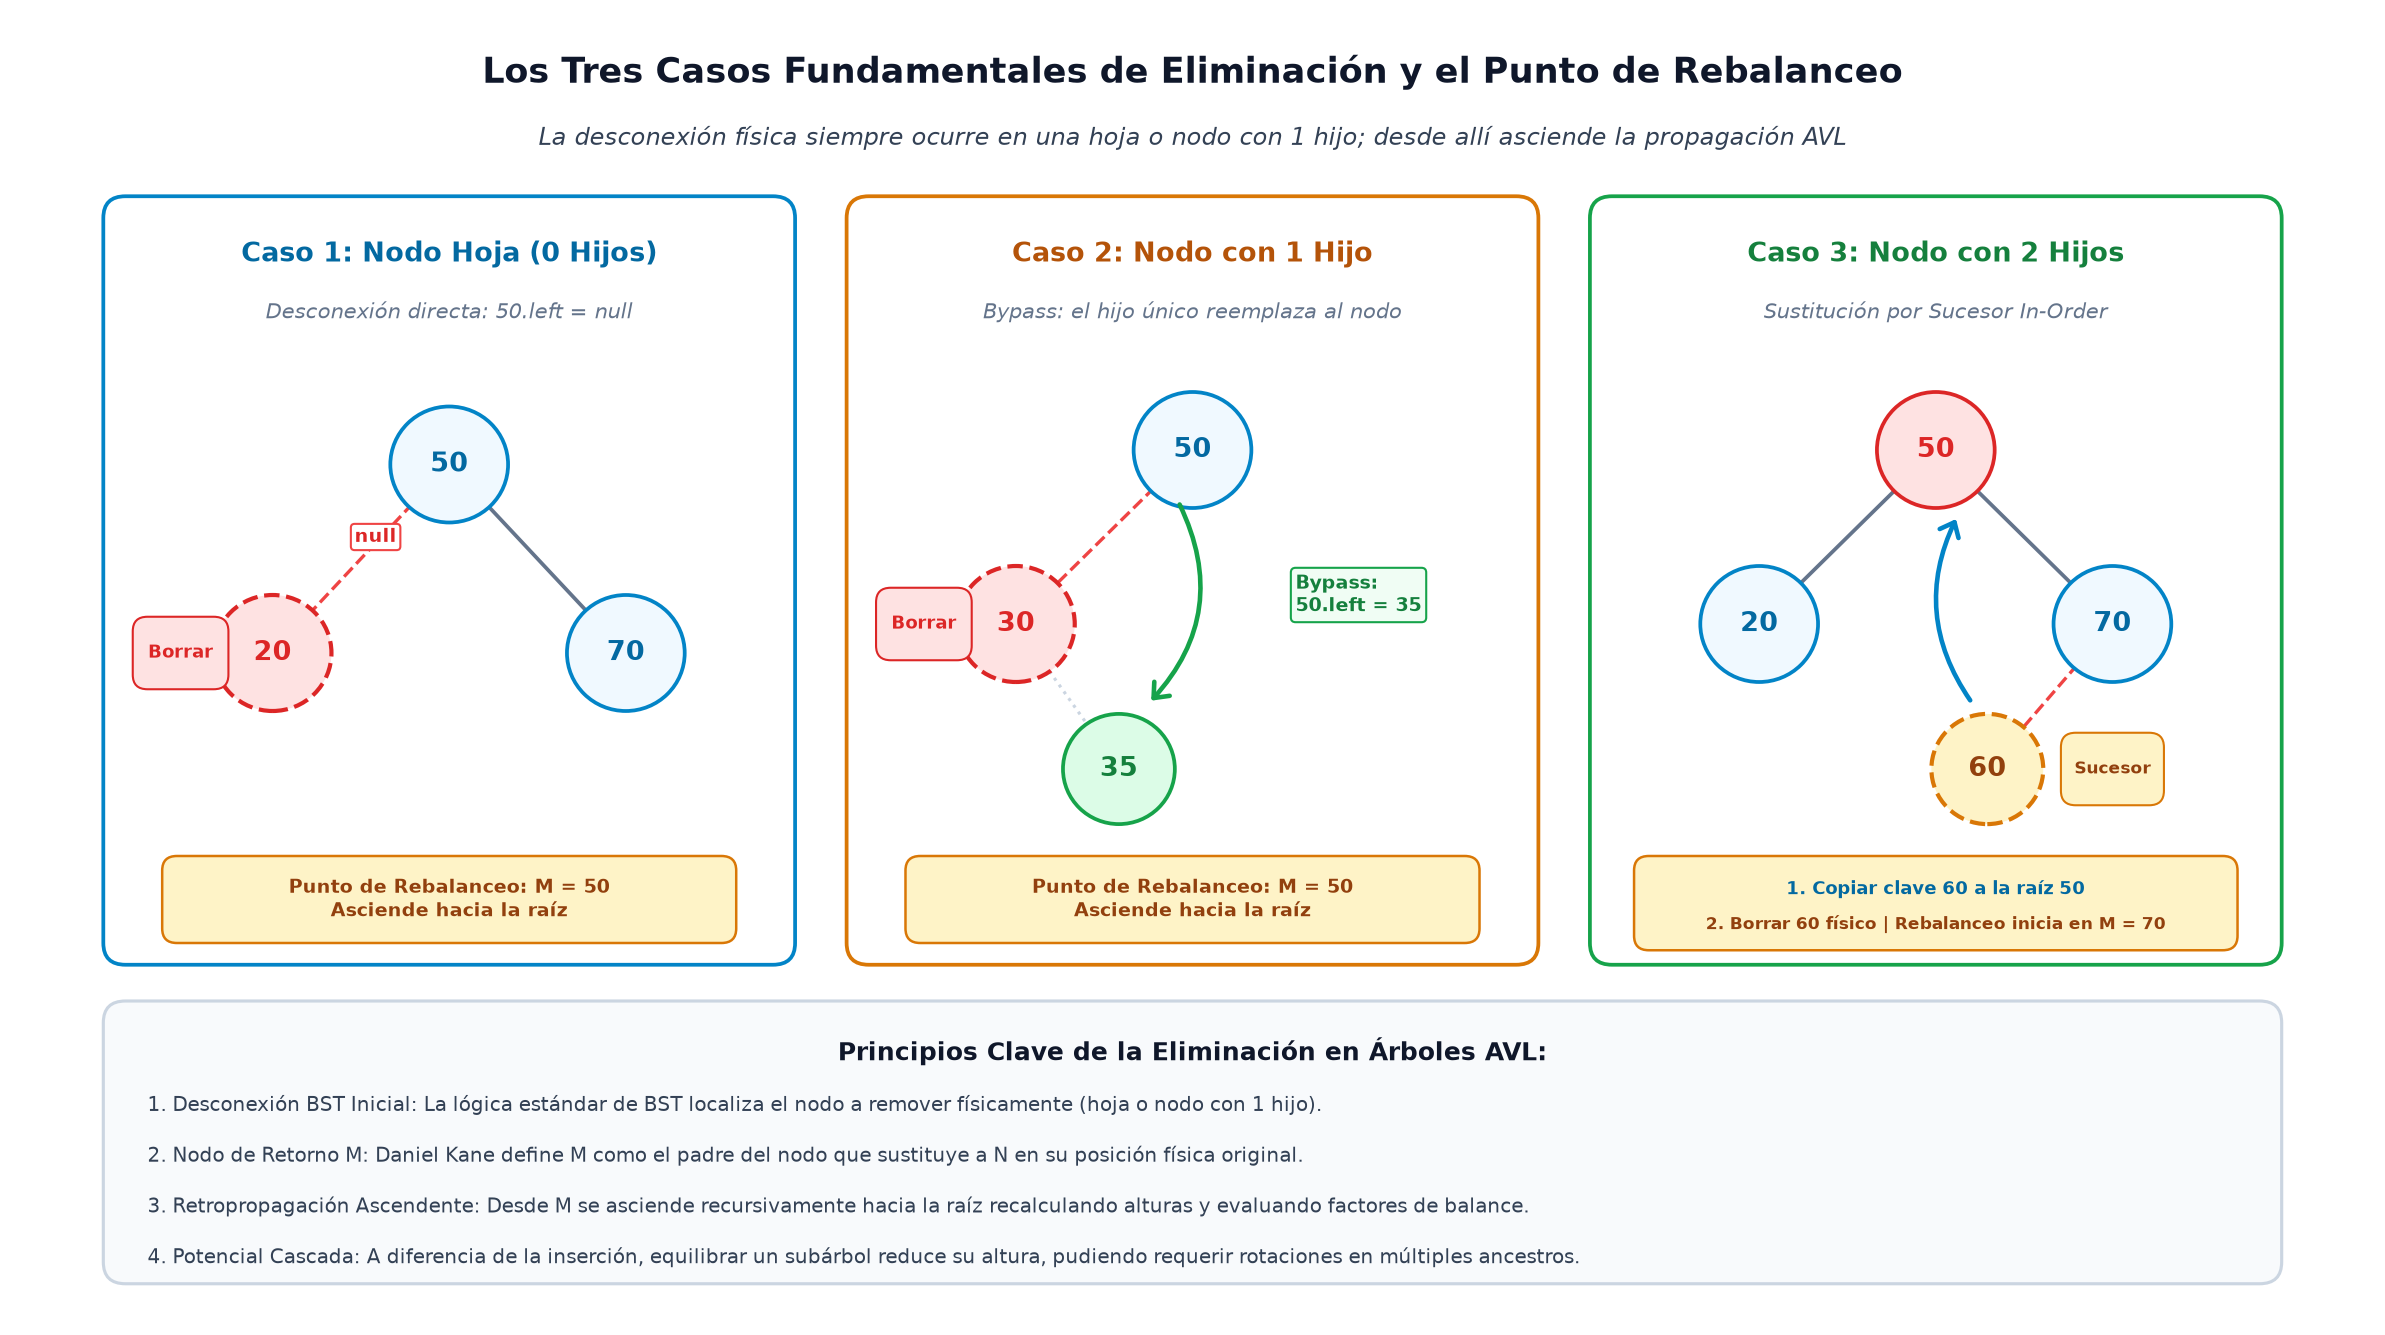
  <p><em>Figura 1: Representación de los tres casos de eliminación BST aplicados a un árbol AVL. Nótese cómo en el Caso 3 la eliminación lógica de 50 se convierte en la eliminación física del sucesor 60, iniciando el rebalanceo en su padre inmediato.</em></p>
</div>


## 3. Mecánica de Rebalanceo tras la Eliminación: Casos y Factor de Balance

Una vez que un subárbol pierde un nodo, ascendemos por sus ancestros. En cada nodo $Z$ del camino:
1. Se actualiza su altura:
$$\text{height}(Z) = 1 + \max(\text{height}(Z.\text{left}), \text{height}(Z.\text{right}))$$
2. Se evalúa su Factor de Balance:
$$BF(Z) = \text{height}(Z.\text{left}) - \text{height}(Z.\text{right})$$

Si $|BF(Z)| \le 1$, el nodo permanece en equilibrio y continuamos ascendiendo. Sin embargo, si $|BF(Z)| = 2$ o $BF(Z) = -2$, se ha producido un desbalanceo y debemos aplicar una rotación.

### 3.1 Desbalanceo a la Izquierda ($BF(Z) = +2$)
El subárbol izquierdo es dos niveles más alto que el derecho (esto ocurre porque se eliminó un nodo en el subárbol derecho de $Z$). Sea $Y = Z.\text{left}$:

* **Caso LL Clásico ($BF(Y) = +1$):** El subárbol exterior izquierdo de $Y$ es el más alto. Se resuelve con una **Rotación Simple a la Derecha** (`RotateRight(Z)`). La altura del subárbol de $Z$ **disminuye en 1**, por lo que la contracción puede propagar desbalance hacia arriba.
* **Caso LR Zigzag ($BF(Y) = -1$):** El subárbol interior derecho de $Y$ es el más alto. Se resuelve con una **Rotación Doble Izquierda-Derecha** (`RotateLeft(Y)` seguido de `RotateRight(Z)`). La altura del subárbol también **disminuye en 1**, propagando potencialmente el desbalance.
* **Caso L0: ¡La Singularidad de la Eliminación! ($BF(Y) = 0$):**
  * ¿Por qué ocurre? Este caso ocurre si los dos subárboles de $Y$ tienen exactamente la misma altura, y la eliminación de un nodo en el subárbol derecho de $Z$ causó que $Z$ quedara desbalanceado con $BF(Z) = +2$.
  * **¡Este caso NUNCA puede presentarse durante una inserción!** En la inserción, un nuevo nodo solo puede alterar un único camino, por lo que el hijo que causa el desbalance siempre tiene $BF = \pm 1$.
  * **Resolución:** Se resuelve mediante una **Rotación Simple a la Derecha** (`RotateRight(Z)`).
  * **Efecto Crítico:** Tras la rotación, el nuevo nodo raíz $Y$ tendrá un factor de balance de $-1$, y su nueva altura será **idéntica a la altura que tenía el subárbol antes de la eliminación**. Por lo tanto, el padre de $Z$ no percibe ningún cambio en la altura de su rama y **la cascada de rebalanceo se detiene de inmediato**.

### 3.2 Desbalanceo a la Derecha ($BF(Z) = -2$)
El subárbol derecho es dos niveles más alto que el izquierdo (se eliminó un nodo en el subárbol izquierdo de $Z$). Sea $Y = Z.\text{right}$:

* **Caso RR Clásico ($BF(Y) = -1$):** Se resuelve con una **Rotación Simple a la Izquierda** (`RotateLeft(Z)`). Altura disminuye en 1.
* **Caso RL Zagzig ($BF(Y) = +1$):** Se resuelve con una **Rotación Doble Derecha-Izquierda** (`RotateRight(Y)` seguido de `RotateLeft(Z)`). Altura disminuye en 1.
* **Caso R0 ($BF(Y) = 0$):** Se resuelve con una **Rotación Simple a la Izquierda** (`RotateLeft(Z)`). La altura se mantiene y la propagación se detiene.

### 3.3 Tabla Decisional Completa de Rebalanceo Post-Eliminación

| Factor de Balance Nodo ($BF(Z)$) | Factor de Balance Hijo ($BF(Y)$) | Caso Algorítmico | Rotación Requerida | ¿Varía la Altura? | ¿Continúa la Cascada? |
| :---: | :---: | :---: | :---: | :---: | :---: |
| **$+2$** (Izquierda pesada) | **$+1$** | Left-Left (LL) | `RotateRight(Z)` | Disminuye en 1 | **Sí** (puede propagar) |
| **$+2$** (Izquierda pesada) | **$0$** | **Left-Zero (L0)** | `RotateRight(Z)` | **NO varía** | **NO (Se detiene)** |
| **$+2$** (Izquierda pesada) | **$-1$** | Left-Right (LR) | `RotateLeft(Y)` + `RotateRight(Z)` | Disminuye en 1 | **Sí** (puede propagar) |
| **$-2$** (Derecha pesada) | **$-1$** | Right-Right (RR) | `RotateLeft(Z)` | Disminuye en 1 | **Sí** (puede propagar) |
| **$-2$** (Derecha pesada) | **$0$** | **Right-Zero (R0)** | `RotateLeft(Z)` | **NO varía** | **NO (Se detiene)** |
| **$-2$** (Derecha pesada) | **$+1$** | Right-Left (RL) | `RotateRight(Y)` + `RotateLeft(Z)` | Disminuye en 1 | **Sí** (puede propagar) |

A continuación se ilustra con máxima claridad la singularidad del caso $BF(\text{hijo}) = 0$ frente a los casos clásicos:

<div align="center">
  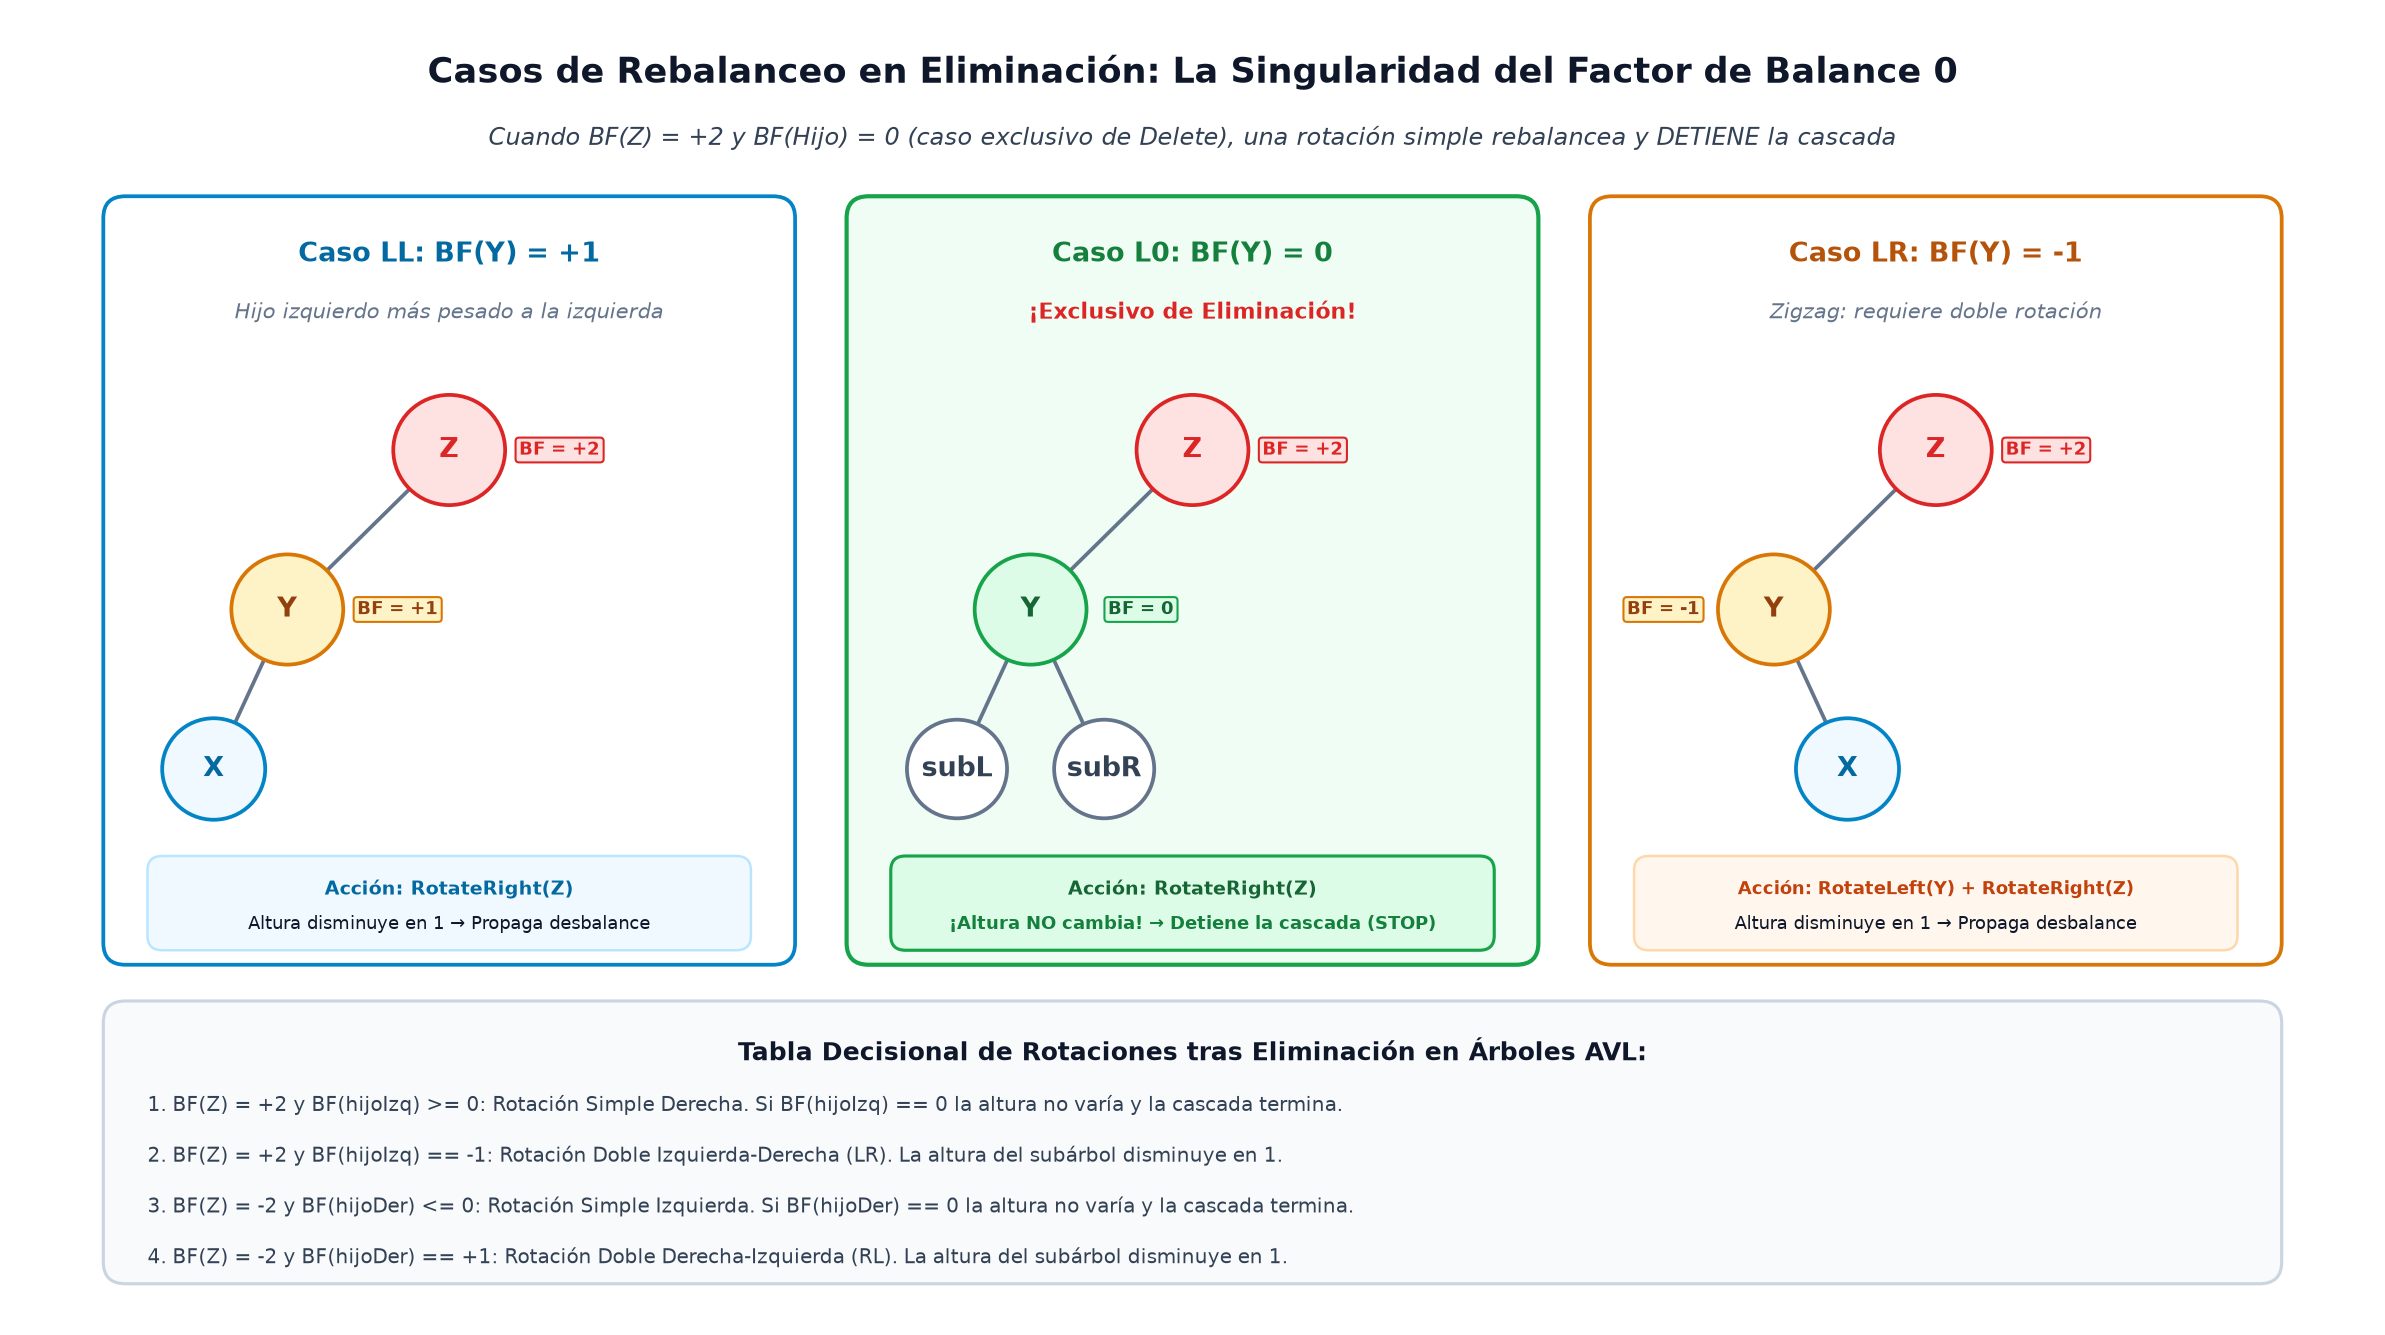
  <p><em>Figura 2: Comparación de los tres casos de rebalanceo cuando $BF(Z) = +2$. El panel central resalta el caso exclusivo de eliminación $BF(Y)=0$, donde una rotación simple rebalancea el nodo sin reducir la altura total del subárbol, deteniendo la propagación.</em></p>
</div>


## 4. La Cascada de Rotaciones: Por qué Inserción es $O(1)$ rotaciones pero Eliminación es $O(\log n)$

Una de las preguntas teóricas más frecuentes y fascinantes en estructuras de datos avanzadas es: **¿Por qué la inserción en un árbol AVL requiere a lo sumo 1 rotación, mientras que la eliminación puede requerir hasta $O(\log n)$ rotaciones?**

### 4.1 La Dinámica de Alturas: Restauración vs. Contracción

* **Dinámica en Inserción:**
  1. Estado inicial: Subárbol balanceado de altura $h$.
  2. Inserción: Entra un nuevo nodo hoja; la altura del subárbol se incrementa a $h+1$.
  3. Desbalance: El ancestro $Z$ más profundo queda con $|BF(Z)| = 2$.
  4. Rotación en $Z$: La rotación (ya sea simple o doble) reconfigura los nodos de modo que la nueva raíz del subárbol tiene altura $h$.
  5. **Conclusión:** Como la altura volvió a ser $h$ (exactamente la que tenía antes de la inserción), el padre de $Z$ no experimenta ninguna variación en la altura de su rama. Ningún ancestro superior puede desbalancearse. El número de rotaciones es **estrictamente $1$ (o $0$ si no hubo desbalance)**. Cota: $O(1)$ rotaciones.

* **Dinámica en Eliminación:**
  1. Estado inicial: Subárbol balanceado de altura $h$.
  2. Eliminación: Se remueve un nodo; la altura de una de sus ramas disminuye, provocando que la altura del subárbol caiga a $h-1$.
  3. Desbalance: El ancestro $Z$ queda con $|BF(Z)| = 2$.
  4. Rotación en $Z$: Salvo en el caso especial $BF(\text{hijo}) = 0$, la rotación equilibra $Z$, pero la nueva altura del subárbol reestructurado queda en **$h-1$**.
  5. **Conclusión:** El padre de $Z$ percibe que su hijo ahora tiene altura $h-1$ en lugar de $h$. Esta pérdida de altura puede provocar que el padre quede a su vez con $|BF(\text{padre})| = 2$, exigiendo una **segunda rotación**. Este efecto dominó puede propagarse sucesivamente a través del abuelo, bisabuelo y así sucesivamente hasta la raíz.

### 4.2 Análisis del Peor Caso de Propagación
En el peor escenario posible (árboles mínimos de AVL o estructuras tipo árbol de Fibonacci), una única llamada a `delete` puede requerir una rotación en **cada nivel del árbol**:
$$\text{Número de rotaciones} \le \text{altura}(T) \le 1.44 \log_2(n)$$

Por consiguiente, el número máximo de rotaciones en eliminación es $O(\log n)$.

### 4.3 Resumen Comparativo Asintótico

| Operación | Complejidad Temporal | Complejidad Espacial (Recursión) | Número Máximo de Rotaciones |
| :--- | :---: | :---: | :---: |
| **Búsqueda (`contains`)** | $O(\log n)$ | $O(1)$ o $O(\log n)$ | $0$ (operación de sólo lectura) |
| **Inserción (`insert`)** | $O(\log n)$ | $O(\log n)$ | **$\le 1$ rotación** ($O(1)$ rotaciones) |
| **Eliminación (`delete`)** | $O(\log n)$ | $O(\log n)$ | **$\le \lfloor 1.44 \log_2 n \rfloor$ rotaciones** ($O(\log n)$ rotaciones) |

A continuación se esquematiza la cascada de rebalanceo:

<div align="center">
  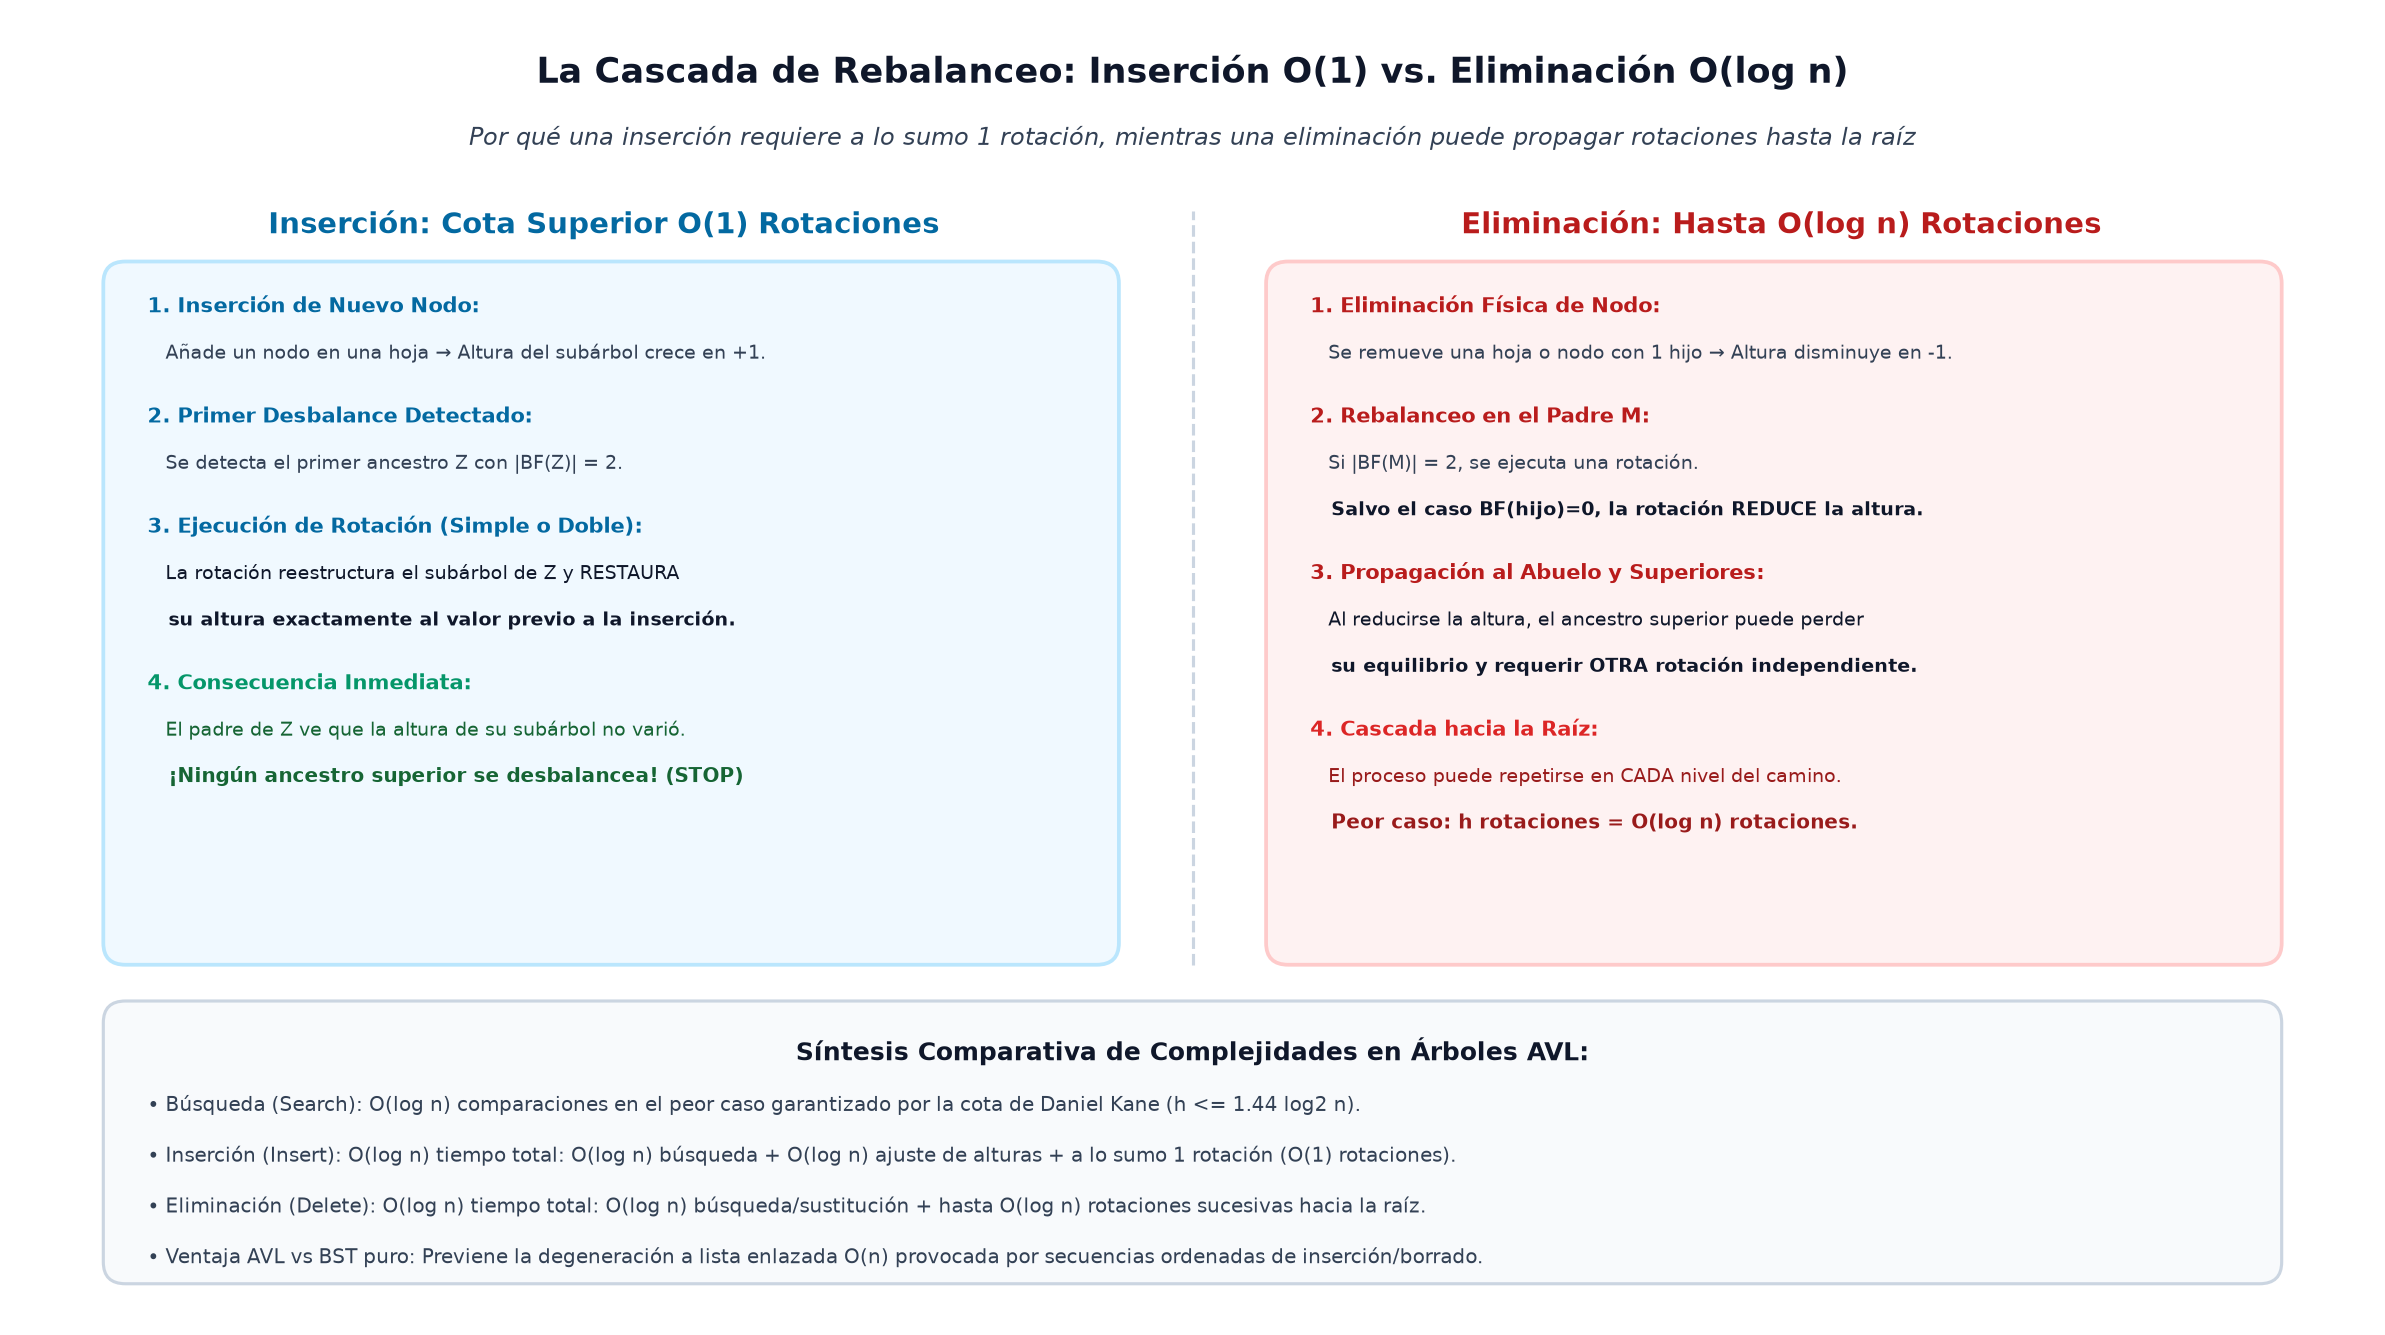
  <p><em>Figura 3: Comparación estructural entre la estabilización inmediata en la inserción ($O(1)$ rotaciones) y la propagación vertical en cascada durante la eliminación ($O(\log n)$ rotaciones).</em></p>
</div>


### Demostración 1: El Algoritmo de Eliminación AVL (`DemoAVLDelete.java`)

A continuación implementamos el algoritmo de eliminación con rebalanceo automático en Java. El programa inserta una secuencia de valores para construir un árbol AVL balanceado, muestra su estado y factores de balance, y luego elimina nodos en diferentes escenarios (nodo hoja, nodo con 1 hijo, y nodo con 2 hijos que provoca rebalanceo).


In [1]:
%%writefile DemoAVLDelete.java
/**
 * Demostración Interactiva del Algoritmo de Eliminación en Árboles AVL.
 * Universidad Nacional de Colombia - Estructuras de Datos
 */
public class DemoAVLDelete {

    // Clase Nodo interna
    static class Node {
        int key;
        int height;
        Node left, right;

        Node(int key) {
            this.key = key;
            this.height = 1; // Altura de nodo hoja = 1
        }
    }

    // Métodos auxiliares de altura y balance
    static int height(Node n) {
        return (n == null) ? 0 : n.height;
    }

    static int getBalance(Node n) {
        return (n == null) ? 0 : height(n.left) - height(n.right);
    }

    // Rotación Simple a la Derecha
    static Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;

        // Reasignación de punteros
        x.right = y;
        y.left = t2;

        // Actualización de alturas (primero el hijo 'y', luego la nueva raíz 'x')
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));

        return x;
    }

    // Rotación Simple a la Izquierda
    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node t2 = y.left;

        // Reasignación de punteros
        y.left = x;
        x.right = t2;

        // Actualización de alturas
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));

        return y;
    }

    // Inserción AVL recursiva
    static Node insert(Node node, int key) {
        if (node == null) return new Node(key);

        if (key < node.key) {
            node.left = insert(node.left, key);
        } else if (key > node.key) {
            node.right = insert(node.right, key);
        } else {
            return node; // No se permiten duplicados
        }

        // Actualizar altura
        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBalance(node);

        // Rebalanceo en Inserción (a lo sumo 1 rotación)
        if (bf > 1 && key < node.left.key) return rotateRight(node);      // LL
        if (bf < -1 && key > node.right.key) return rotateLeft(node);     // RR
        if (bf > 1 && key > node.left.key) {                              // LR
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && key < node.right.key) {                             // RL
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }

        return node;
    }

    // Búsqueda del nodo con clave mínima (Sucesor In-Order)
    static Node findMin(Node node) {
        Node curr = node;
        while (curr.left != null) {
            curr = curr.left;
        }
        return curr;
    }

    // Algoritmo Completo de Eliminación AVL
    static Node delete(Node root, int key) {
        // PASO 1: Eliminación estándar en BST
        if (root == null) return null;

        if (key < root.key) {
            root.left = delete(root.left, key);
        } else if (key > root.key) {
            root.right = delete(root.right, key);
        } else {
            // ¡Nodo encontrado!
            // Casos 1 y 2: Cero o Un hijo
            if (root.left == null || root.right == null) {
                Node temp = (root.left != null) ? root.left : root.right;
                if (temp == null) {
                    // Caso 1: Hoja
                    root = null;
                } else {
                    // Caso 2: Un solo hijo
                    root = temp;
                }
            } else {
                // Caso 3: Dos hijos
                // Obtener el sucesor in-order (mínimo del subárbol derecho)
                Node successor = findMin(root.right);
                root.key = successor.key;
                // Eliminar el sucesor en el subárbol derecho
                root.right = delete(root.right, successor.key);
            }
        }

        // Si el árbol quedó vacío tras borrar el único nodo
        if (root == null) return null;

        // PASO 2: Actualizar altura del nodo actual
        root.height = 1 + Math.max(height(root.left), height(root.right));

        // PASO 3: Obtener factor de balance
        int bf = getBalance(root);

        // PASO 4: Casos de Rebalanceo en Eliminación
        // Caso LL / L0: Izquierda pesada, hijo izquierdo >= 0
        if (bf > 1 && getBalance(root.left) >= 0) {
            return rotateRight(root);
        }

        // Caso LR: Izquierda pesada, hijo izquierdo < 0
        if (bf > 1 && getBalance(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }

        // Caso RR / R0: Derecha pesada, hijo derecho <= 0
        if (bf < -1 && getBalance(root.right) <= 0) {
            return rotateLeft(root);
        }

        // Caso RL: Derecha pesada, hijo derecho > 0
        if (bf < -1 && getBalance(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }

        return root;
    }

    // Recorrido In-Order con alturas y balances
    static void printInOrder(Node root) {
        if (root != null) {
            printInOrder(root.left);
            System.out.printf("[Clave: %2d | Altura: %d | BF: %2d]  ", root.key, root.height, getBalance(root));
            printInOrder(root.right);
        }
    }

    public static void main(String[] args) {
        System.out.println("=== DEMOSTRACIÓN: ELIMINACIÓN EN ÁRBOLES AVL ===");
        Node root = null;
        int[] valores = {9, 5, 10, 0, 6, 11, -1, 1, 2};

        System.out.print("Insertando claves: ");
        for (int v : valores) {
            System.out.print(v + " ");
            root = insert(root, v);
        }
        System.out.println("\n\n--- Árbol AVL Inicial (In-Order) ---");
        printInOrder(root);
        System.out.printf("\nRaíz actual: %d (Altura total: %d, BF: %d)\n", root.key, root.height, getBalance(root));

        // 1. Eliminar una hoja que no causa desbalance
        System.out.println("\n>>> Eliminando clave 11 (nodo hoja)...");
        root = delete(root, 11);
        printInOrder(root);
        System.out.printf("\nRaíz actual: %d (Altura total: %d, BF: %d)\n", root.key, root.height, getBalance(root));

        // 2. Eliminar clave 10 (nodo interno que causa rebalanceo en raíz)
        System.out.println("\n>>> Eliminando clave 10 (provoca rebalanceo hacia la raíz)...");
        root = delete(root, 10);
        printInOrder(root);
        System.out.printf("\nNueva raíz tras rebalanceo: %d (Altura total: %d, BF: %d)\n", root.key, root.height, getBalance(root));

        // 3. Eliminar la raíz actual (nodo con dos hijos)
        int raizAntigua = root.key;
        System.out.printf("\n>>> Eliminando la raíz actual (%d, nodo con dos hijos)...\n", raizAntigua);
        root = delete(root, raizAntigua);
        printInOrder(root);
        System.out.printf("\nNueva raíz tras sustitución de sucesor: %d (Altura: %d, BF: %d)\n", root.key, root.height, getBalance(root));

        System.out.println("\n¡Todos los invariantes AVL e In-Order se mantienen estrictamente!");
    }
}


Writing DemoAVLDelete.java


In [2]:
!javac -encoding UTF-8 DemoAVLDelete.java
!java DemoAVLDelete


[0.016s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.016s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
=== DEMOSTRACIÓN: ELIMINACIÓN EN ÁRBOLES AVL ===
Insertando claves: 9 5 10 0 6 11 -1 1 2 

--- Árbol AVL Inicial (In-Order) ---
[Clave: -1 | Altura: 1 | BF:  0]  [Clave:  0 | Altura: 2 | BF:  1]  [Clave:  1 | Altura: 3 | BF:  0]  [Clave:  2 | Altura: 1 | BF:  0]  [Clave:  5 | Altura: 2 | BF:  0]  [Clave:  6 | Altura: 1 | BF:  0]  [Clave:  9

## 6. El Modelo Visual de Galles (USFCA Visualizer Trace) y Visualizador en Consola

El simulador interactivo de estructuras de datos desarrollado por el **Prof. David Galles** en la Universidad de San Francisco ([USFCA AVL Tree Visualization](https://www.cs.usfca.edu/~galles/visualization/AVLtree.html)) es el estándar de referencia mundial para comprender la dinámica en tiempo real de los árboles AVL.

En dicho entorno, cada nodo se dibuja con su clave en el centro y su factor de balance en la esquina superior. Cuando se solicita eliminar una clave:
1. Se resalta en verde el camino de búsqueda descendente hasta hallar el nodo objetivo.
2. Si el nodo tiene dos hijos, el algoritmo desciende al subárbol derecho y busca el valor más a la izquierda (sucesor), animando el intercambio de valores.
3. Se remueve el nodo y se muestra en rojo el camino de retroceso ascendente.
4. En cada nodo ancestro, se recalcula la altura. Si se detecta un valor $|BF| = 2$, el simulador "congela" el árbol, traza un arco de rotación y despliega la animación de pivoteo de punteros.

A continuación se presenta la traza conceptual exacta de una eliminación de nodo hoja que desencadena una rotación simple a la izquierda (RR):

<div align="center">
  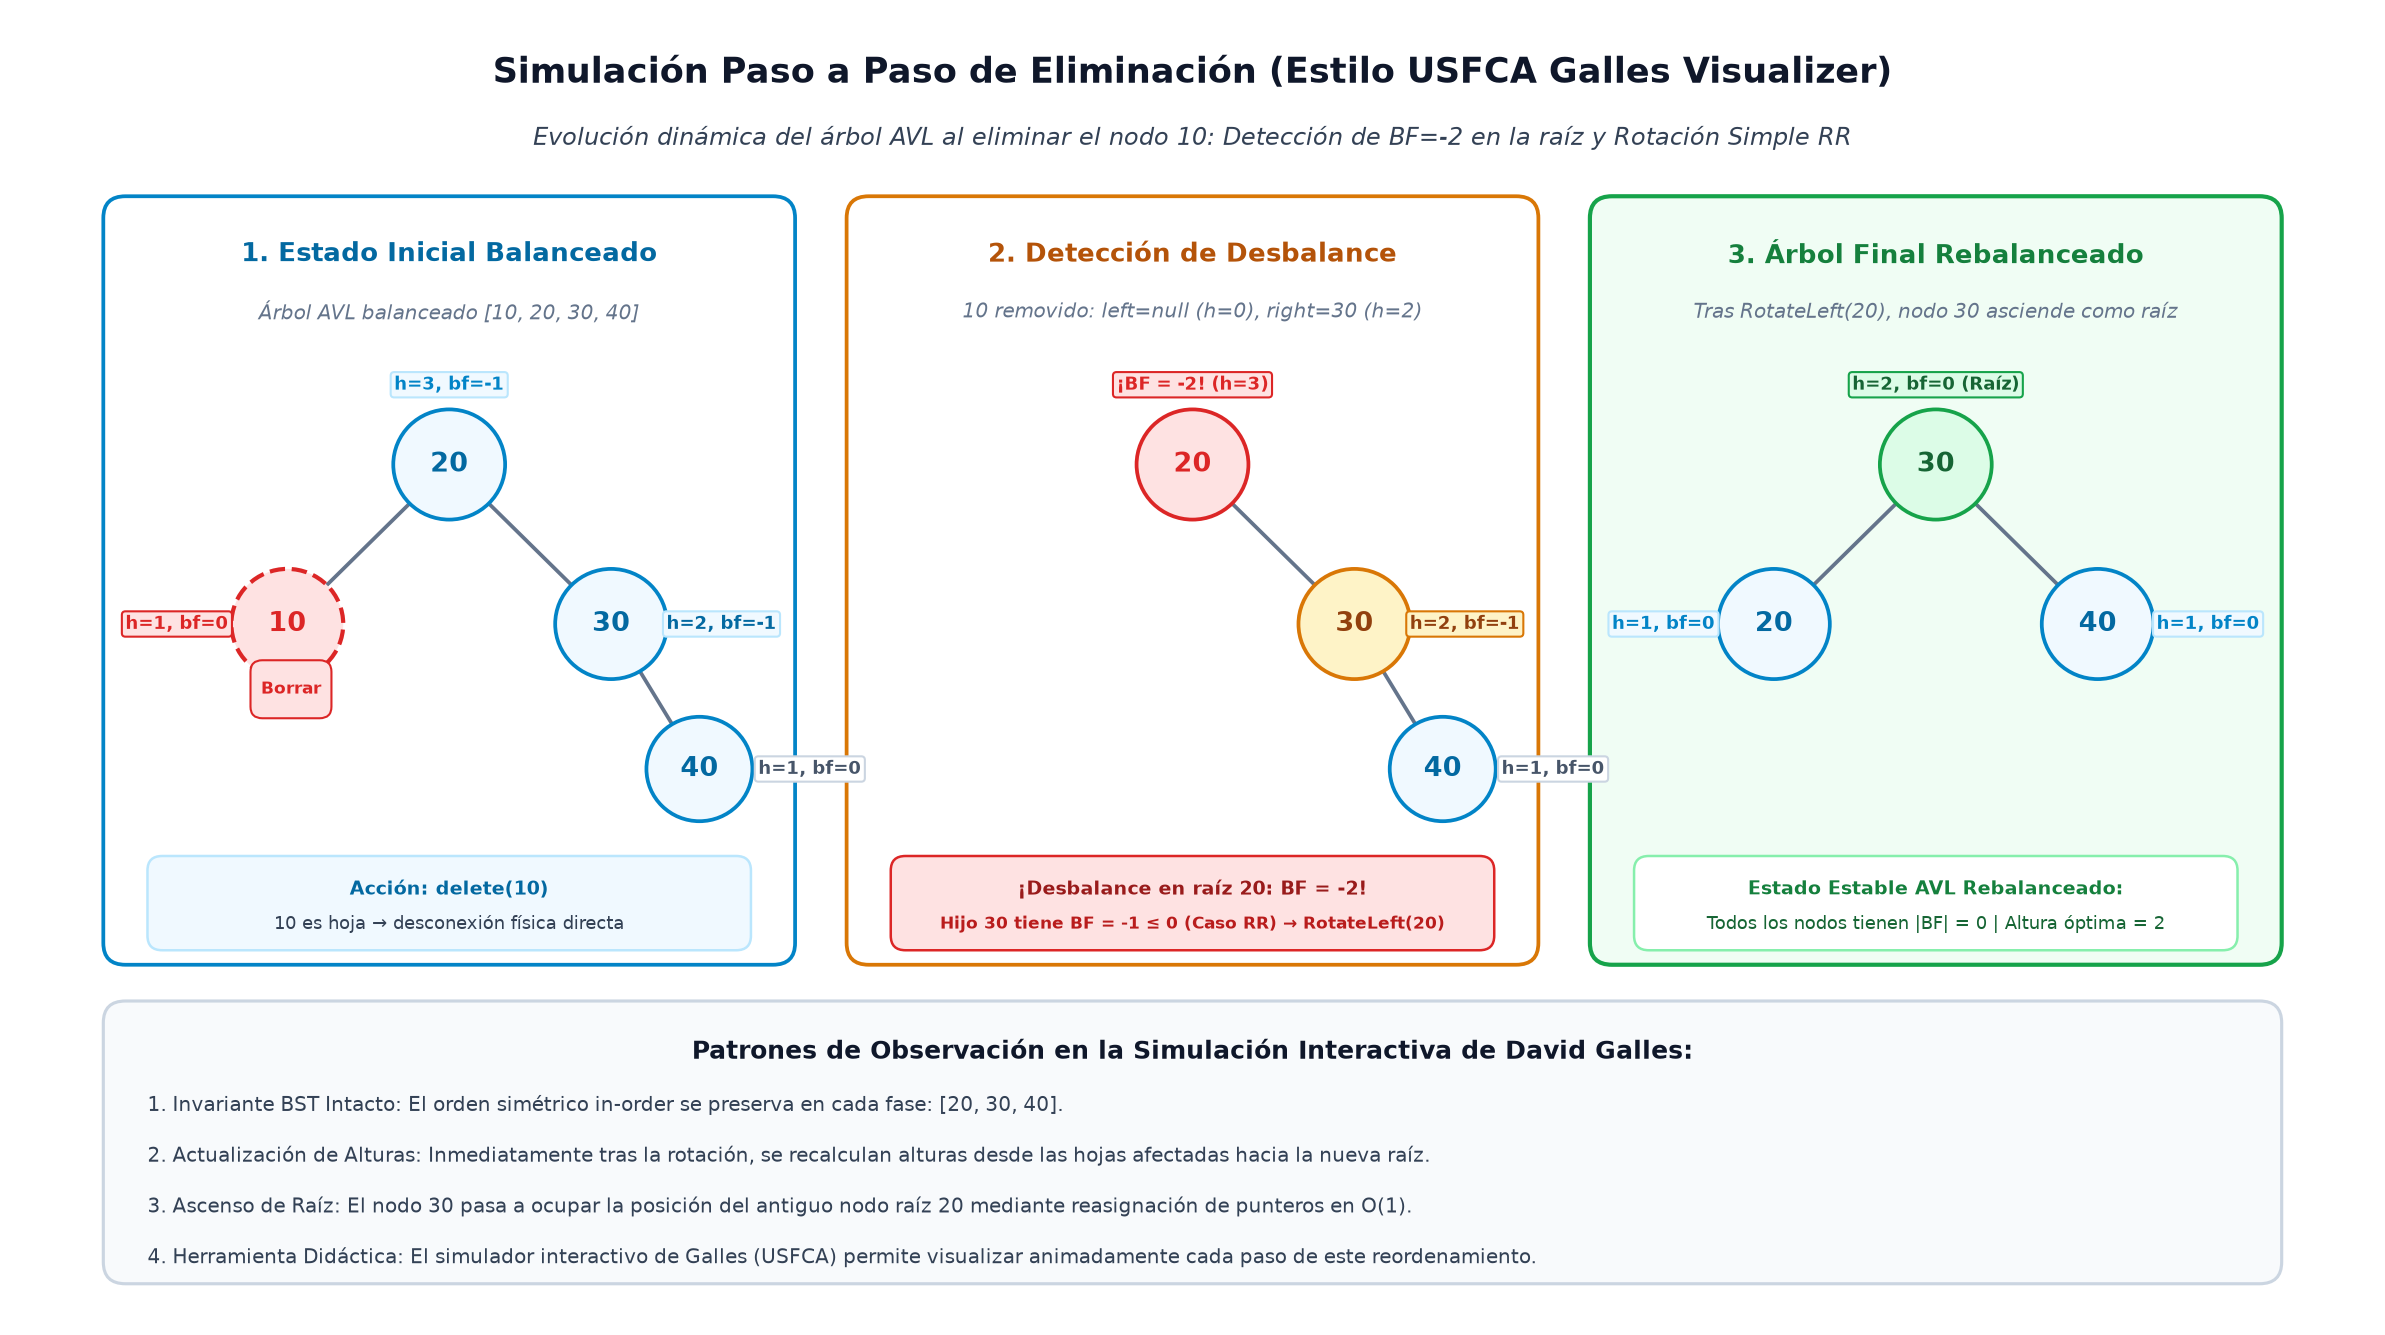
  <p><em>Figura 4: Simulación paso a paso de la eliminación de la clave 10 en un árbol AVL [10, 20, 30, 40]. Se observa el desbalance en la raíz 20 (BF = -2) y su reestructuración mediante RotateLeft(20), estableciendo a 30 como nueva raíz balanceada.</em></p>
</div>


### Demostración 2: Visualizador Jerárquico de Árboles AVL en Consola (`VisualizadorArbolAVL.java`)

Para poder replicar la experiencia visual de Galles directamente en su terminal de Java o Google Colab sin depender de librerías gráficas externas, implementamos un algoritmo de impresión jerárquico 2D recursivo. Este método dibuja el árbol orientado horizontalmente mostrando las ramas, claves, alturas y factores de balance.


In [3]:
%%writefile VisualizadorArbolAVL.java
/**
 * Visualizador Gráfico en Consola para Árboles AVL (Estilo Galles).
 * Universidad Nacional de Colombia - Estructuras de Datos
 */
public class VisualizadorArbolAVL {

    static class Node {
        int key;
        int height;
        Node left, right;
        Node(int key) { this.key = key; this.height = 1; }
    }

    static int height(Node n) { return n == null ? 0 : n.height; }
    static int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node t2 = y.left;
        y.left = x;
        x.right = t2;
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));
        return y;
    }

    static Node insert(Node node, int key) {
        if (node == null) return new Node(key);
        if (key < node.key) node.left = insert(node.left, key);
        else if (key > node.key) node.right = insert(node.right, key);
        else return node;

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBF(node);

        if (bf > 1 && key < node.left.key) return rotateRight(node);
        if (bf < -1 && key > node.right.key) return rotateLeft(node);
        if (bf > 1 && key > node.left.key) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && key < node.right.key) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        return node;
    }

    static Node findMin(Node node) {
        while (node.left != null) node = node.left;
        return node;
    }

    static Node delete(Node root, int key) {
        if (root == null) return null;
        if (key < root.key) root.left = delete(root.left, key);
        else if (key > root.key) root.right = delete(root.right, key);
        else {
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            } else {
                Node succ = findMin(root.right);
                root.key = succ.key;
                root.right = delete(root.right, succ.key);
            }
        }
        if (root == null) return null;

        root.height = 1 + Math.max(height(root.left), height(root.right));
        int bf = getBF(root);

        if (bf > 1 && getBF(root.left) >= 0) return rotateRight(root);
        if (bf > 1 && getBF(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        if (bf < -1 && getBF(root.right) <= 0) return rotateLeft(root);
        if (bf < -1 && getBF(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }
        return root;
    }

    // Algoritmo de Impresión Jerárquica en Consola (In-Order Inverso con Prefijos)
    public static void imprimirArbol(Node root) {
        imprimirArbolHelper(root, "", true);
    }

    private static void imprimirArbolHelper(Node node, String prefijo, boolean esCola) {
        if (node != null) {
            // Imprimir primero subárbol derecho (arriba)
            imprimirArbolHelper(node.right, prefijo + (esCola ? "│   " : "    "), false);

            // Imprimir nodo actual con altura y BF
            System.out.println(prefijo + (esCola ? "└── " : "┌── ")
                               + "[" + node.key + "] (h=" + node.height + ", bf=" + getBF(node) + ")");

            // Imprimir subárbol izquierdo (abajo)
            imprimirArbolHelper(node.left, prefijo + (esCola ? "    " : "│   "), true);
        }
    }

    public static void main(String[] args) {
        System.out.println("=== VISUALIZACIÓN BIDIMENSIONAL DE ÁRBOLES AVL ===\n");
        Node root = null;
        int[] claves = {50, 25, 75, 15, 35, 65, 85, 10, 20};

        for (int k : claves) root = insert(root, k);

        System.out.println("1. Árbol Inicial tras insertar 9 elementos:");
        imprimirArbol(root);

        System.out.println("\n--------------------------------------------------");
        System.out.println("2. Eliminando clave 75 (nodo interno)...");
        root = delete(root, 75);
        imprimirArbol(root);

        System.out.println("\n--------------------------------------------------");
        System.out.println("3. Eliminando clave 85 (provoca rebalanceo)...");
        root = delete(root, 85);
        imprimirArbol(root);

        System.out.println("\n--------------------------------------------------");
        System.out.println("4. Eliminando clave 50 (la raíz)...");
        root = delete(root, 50);
        imprimirArbol(root);
    }
}


Writing VisualizadorArbolAVL.java


In [4]:
!javac -encoding UTF-8 VisualizadorArbolAVL.java
!java VisualizadorArbolAVL


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
=== VISUALIZACIÓN BIDIMENSIONAL DE ÁRBOLES AVL ===

1. Árbol Inicial tras insertar 9 elementos:
│       ┌── [85] (h=1, bf=0)
│   ┌── [75] (h=2, bf=0)
│   │   └── [65] (h=1, bf=0)
└── [50] (h=4, bf=1)
    │   ┌── [35] (h=1, bf=0)
    └── [25] (h=3, bf=1)
        │   ┌── [20] (h=1, bf=0)
        └── [15] (h=2, bf=0)
            └── [10] (h=1,

## 7. Implementación Completa: Árbol AVL Industrial en Java

A continuación presentamos la arquitectura `ArbolAVL<T extends Comparable<T>>`:
* **Genérica:** Funciona con cualquier tipo comparable (`Integer`, `String`, objetos personalizados).
* **Operaciones Completas:** `insert`, `delete`, `contains`, `findMin`, `findMax`, `height`, `size`, `isEmpty`, `clear`.
* **Recorridos:** `inOrder`, `preOrder`, `postOrder`, y recorrido por niveles en amplitud (`levelOrder`) utilizando una cola `Queue<Node<T>>`.
* **Auditoría de Invariantes:** Método `isBalanced()` que recorre el árbol completo validando que cada nodo cumpla estrictamente $|BF| \le 1$ y que las alturas estén perfectamente sincronizadas.


In [10]:
%%writefile ArbolAVL.java
import java.util.LinkedList;
import java.util.Queue;

/**
 * Implementación Completa y Autónoma de un Árbol AVL Genérico.
 */
public class ArbolAVL<T extends Comparable<T>> {

    // Clase interna para los Nodos
    public static class Node<T> {
        public T data;
        public int height;
        public Node<T> left;
        public Node<T> right;

        public Node(T data) {
            this.data = data;
            this.height = 1;
        }
    }

    private Node<T> root;
    private int size;

    public ArbolAVL() {
        this.root = null;
        this.size = 0;
    }

    public int size() { return size; }
    public boolean isEmpty() { return size == 0; }
    public void clear() { root = null; size = 0; }
    public int height() { return height(root); }

    private int height(Node<T> n) {
        return (n == null) ? 0 : n.height;
    }

    public int getBalance(Node<T> n) {
        return (n == null) ? 0 : height(n.left) - height(n.right);
    }

    // --- ROTACIONES ---
    private Node<T> rotateRight(Node<T> y) {
        Node<T> x = y.left;
        Node<T> t2 = x.right;

        x.right = y;
        y.left = t2;

        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));

        return x;
    }

    private Node<T> rotateLeft(Node<T> x) {
        Node<T> y = x.right;
        Node<T> t2 = y.left;

        y.left = x;
        x.right = t2;

        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));

        return y;
    }

    // --- INSERCIÓN ---
    public void insert(T data) {
        if (data == null) throw new IllegalArgumentException("No se permiten datos nulos");
        root = insert(root, data);
    }

    private Node<T> insert(Node<T> node, T data) {
        if (node == null) {
            size++;
            return new Node<>(data);
        }

        int cmp = data.compareTo(node.data);
        if (cmp < 0) {
            node.left = insert(node.left, data);
        } else if (cmp > 0) {
            node.right = insert(node.right, data);
        } else {
            return node; // Clave duplicada: no se inserta
        }

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBalance(node);

        // Casos de balanceo en inserción
        if (bf > 1 && data.compareTo(node.left.data) < 0) return rotateRight(node);
        if (bf < -1 && data.compareTo(node.right.data) > 0) return rotateLeft(node);
        if (bf > 1 && data.compareTo(node.left.data) > 0) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && data.compareTo(node.right.data) < 0) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }

        return node;
    }

    // --- BÚSQUEDA ---
    public boolean contains(T data) {
        return contains(root, data);
    }

    private boolean contains(Node<T> node, T data) {
        if (node == null) return false;
        int cmp = data.compareTo(node.data);
        if (cmp < 0) return contains(node.left, data);
        if (cmp > 0) return contains(node.right, data);
        return true;
    }

    public T findMin() {
        if (isEmpty()) throw new IllegalStateException("Árbol vacío");
        return findMinNode(root).data;
    }

    private Node<T> findMinNode(Node<T> node) {
        Node<T> curr = node;
        while (curr.left != null) curr = curr.left;
        return curr;
    }

    public T findMax() {
        if (isEmpty()) throw new IllegalStateException("Árbol vacío");
        Node<T> curr = root;
        while (curr.right != null) curr = curr.right;
        return curr.data;
    }

    // --- ELIMINACIÓN ---
    public boolean delete(T data) {
        if (!contains(data)) return false;
        root = delete(root, data);
        size--;
        return true;
    }

    private Node<T> delete(Node<T> root, T data) {
        if (root == null) return null;

        int cmp = data.compareTo(root.data);
        if (cmp < 0) {
            root.left = delete(root.left, data);
        } else if (cmp > 0) {
            root.right = delete(root.right, data);
        } else {
            // Caso 1 o 2: 0 o 1 hijo
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            } else {
                // Caso 3: 2 hijos
                Node<T> succ = findMinNode(root.right);
                root.data = succ.data;
                root.right = delete(root.right, succ.data);
            }
        }

        if (root == null) return null;

        // Actualizar altura
        root.height = 1 + Math.max(height(root.left), height(root.right));
        int bf = getBalance(root);

        // Casos de balanceo en eliminación (soporta BF hijo == 0)
        if (bf > 1 && getBalance(root.left) >= 0) return rotateRight(root);
        if (bf > 1 && getBalance(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        if (bf < -1 && getBalance(root.right) <= 0) return rotateLeft(root);
        if (bf < -1 && getBalance(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }

        return root;
    }

    // --- RECORRIDOS ---
    public void printInOrder() {
        printInOrder(root);
        System.out.println();
    }

    private void printInOrder(Node<T> n) {
        if (n != null) {
            printInOrder(n.left);
            System.out.print(n.data + " ");
            printInOrder(n.right);
        }
    }

    public void printLevelOrder() {
        if (root == null) return;
        Queue<Node<T>> q = new LinkedList<>();
        q.add(root);
        while (!q.isEmpty()) {
            int levelSize = q.size();
            for (int i = 0; i < levelSize; i++) {
                Node<T> curr = q.poll();
                System.out.print(curr.data + "(bf=" + getBalance(curr) + ") ");
                if (curr.left != null) q.add(curr.left);
                if (curr.right != null) q.add(curr.right);
            }
            System.out.println();
        }
    }

    // --- VALIDACIÓN DE INTEGRIDAD AVL ---
    public boolean isAVL() {
        return isAVL(root);
    }

    private boolean isAVL(Node<T> n) {
        if (n == null) return true;
        int bf = getBalance(n);
        if (Math.abs(bf) > 1) return false;
        int expectedH = 1 + Math.max(height(n.left), height(n.right));
        if (n.height != expectedH) return false;
        return isAVL(n.left) && isAVL(n.right);
    }

    // --- PROGRAMA PRINCIPAL DE PRUEBA ---
    public static void main(String[] args) {
        System.out.println("=== PRUEBA DE ÁRBOL AVL INDUSTRIAL GENÉRICO ===");
        ArbolAVL<Integer> arbol = new ArbolAVL<>();

        int[] datos = {40, 20, 60, 10, 30, 50, 70, 25, 35};
        for (int d : datos) arbol.insert(d);

        System.out.println("1. Tamaño total: " + arbol.size() + ", Altura: " + arbol.height());
        System.out.print("2. Recorrido In-Order: ");
        arbol.printInOrder();

        System.out.println("3. Recorrido por Niveles (Amplitud):");
        arbol.printLevelOrder();

        System.out.println("4. ¿Cumple Invariante AVL? " + arbol.isAVL());
        System.out.println("5. Mínimo: " + arbol.findMin() + ", Máximo: " + arbol.findMax());

        System.out.println("\n>>> Eliminando claves 10, 20, 40 (raíz)...");
        arbol.delete(10);
        arbol.delete(20);
        arbol.delete(40);

        System.out.print("6. In-Order tras eliminaciones: ");
        arbol.printInOrder();
        System.out.println("7. Recorrido por Niveles tras rebalanceos:");
        arbol.printLevelOrder();
        System.out.println("8. ¿Continúa balanceado? " + arbol.isAVL());
        System.out.println("9. Nuevo tamaño: " + arbol.size() + ", Nueva altura: " + arbol.height());
    }
}


Overwriting ArbolAVL.java


In [11]:
!javac -encoding UTF-8 ArbolAVL.java
!java ArbolAVL


[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.000s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
=== PRUEBA DE ÁRBOL AVL INDUSTRIAL GENÉRICO ===
1. Tamaño total: 9, Altura: 4
2. Recorrido In-Order: 10 20 25 30 35 40 50 60 70 
3. Recorrido por Niveles (Amplitud):
40(bf=1) 
20(bf=-1) 60(bf=0) 
10(bf=0) 30(bf=0) 50(bf=0) 70(bf=0) 
25(bf=0) 35(bf=0) 
4. ¿Cumple Invariante AVL? true
5. Mínimo: 10, Máximo: 70

>>> Eliminando claves 10, 20, 4

## 8. Buenas Prácticas y Errores Frecuentes (*Pitfalls*) al Eliminar en AVL

Implementar la eliminación en un árbol balanceado es reconocido como uno de los algoritmos más desafiantes en programación de sistemas. A continuación se detallan los errores más comunes y cómo evitarlos:

### 1. El Error de Condición Estricta en el Hijo ($BF == 0$)
* **El Error:** Muchos programadores copian mecánicamente las condiciones de inserción:
  ```java
  // ¡INCORRECTO EN DELETE!
  if (bf > 1 && getBalance(root.left) > 0) return rotateRight(root); // Falta el >= 0
  ```
* **La Consecuencia:** Si $BF(\text{hijo}) == 0$, el código evalúa la condición como falsa y cae erróneamente en el caso `LR` (rotación doble), corrompiendo la estructura de alturas o ejecutando rotaciones redundantes destructivas.
* **Solución Correcta:** Utilizar **siempre** `>= 0` para el caso izquierdo y `<= 0` para el caso derecho.

### 2. Olvidar Actualizar la Altura Antes de Evaluar el Balance
* **El Error:** Intentar calcular `getBalance(root)` antes de actualizar `root.height = 1 + Math.max(...)`.
* **La Consecuencia:** El balance se calcula con alturas desactualizadas de iteraciones anteriores, dejando nodos desbalanceados invisibles para el algoritmo.

### 3. Asumir que la Rotación Detiene la Recursión (Pensar que es como `insert`)
* **El Error:** Retornar tras una sola rotación sin permitir que la llamada recursiva continúe subiendo hacia la raíz.
* **La Consecuencia:** El árbol se equilibra localmente en un subárbol bajo, pero el abuelo o la raíz permanecen desbalanceados ($|BF| = 2$), violando el invariante AVL global.

### 4. Copiar Referencias en Lugar de Copiar Valores en el Caso 3 (Dos Hijos)
* **El Error:** Intentar intercambiar nodos enteros en la memoria manipulando enlaces de 4 o 5 punteros en lugar de simplemente hacer `root.key = successor.key`.
* **La Consecuencia:** Punteros circulares, fugas de memoria o pérdidas catastróficas de subárboles completos. Copiar el valor simétrico y luego mandar a borrar recursivamente dicho valor en el subárbol derecho es la técnica más limpia y matemáticamente segura.

### 5. No Gestionar Correctamente el Retorno de Nodo Nulo
* **El Error:** No verificar si `root == null` inmediatamente después del bloque de desconexión.
* **La Consecuencia:** Cuando se elimina la última hoja de un subárbol, `root` se vuelve `null`. Si el código inmediatamente intenta ejecutar `root.height = ...`, lanzará un `NullPointerException` fulminante.


## 9. Ejercicios Prácticos de Programación con Pruebas Automatizadas

### Ejercicio 1: Eliminación Básica y Rotaciones Simples
**Objetivo:** Implementar la lógica de desconexión directa de nodos hoja y nodos con un solo hijo, garantizando que el factor de balance se recalcule y se aplique una rotación simple cuando corresponda.

**Enunciado:** Completa los bloques `// TODO:` en el método `deleteSimple(Node root, int key)` para gestionar la desconexión de hojas y nodos con un hijo, aplicando rotaciones simples a la derecha (LL) o a la izquierda (RR).


In [ ]:
%%writefile Ejercicio1EliminacionSimple.java
public class Ejercicio1EliminacionSimple {

    static class Node {
        int key, height;
        Node left, right;
        Node(int k) { key = k; height = 1; }
    }

    static int height(Node n) { return n == null ? 0 : n.height; }
    static int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node t2 = y.left;
        y.left = x;
        x.right = t2;
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));
        return y;
    }

    static Node insert(Node node, int key) {
        if (node == null) return new Node(key);
        if (key < node.key) node.left = insert(node.left, key);
        else if (key > node.key) node.right = insert(node.right, key);
        else return node;

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBF(node);

        if (bf > 1 && key < node.left.key) return rotateRight(node);
        if (bf < -1 && key > node.right.key) return rotateLeft(node);
        return node;
    }

    /**
     * Elimina un nodo con a lo sumo un hijo y rebalancea.
     */
    public static Node deleteSimple(Node root, int key) {
        // TODO: 1. Caso base de búsqueda
        if (root == null) return null;

        // TODO: 2. Navegar hacia la izquierda o derecha
        if (key < root.key) {
            root.left = deleteSimple(root.left, key);
        } else if (key > root.key) {
            root.right = deleteSimple(root.right, key);
        } else {
            // TODO: 3. Nodo encontrado. Gestionar caso hoja y caso 1 hijo
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            }
        }

        // Si quedó vacío
        if (root == null) return null;

        // TODO: 4. Actualizar altura
        root.height = 1 + Math.max(height(root.left), height(root.right));

        // TODO: 5. Calcular balance y ejecutar rotaciones si |BF| > 1
        int bf = getBF(root);
        // Caso LL
        if (bf > 1 && getBF(root.left) >= 0) return rotateRight(root);
        // Caso LR
        if (bf > 1 && getBF(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        // Caso RR
        if (bf < -1 && getBF(root.right) <= 0) return rotateLeft(root);
        // Caso RL
        if (bf < -1 && getBF(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }

        return root;
    }

    public static boolean contains(Node root, int key) {
        if (root == null) return false;
        if (key < root.key) return contains(root.left, key);
        if (key > root.key) return contains(root.right, key);
        return true;
    }

    public static boolean isAVL(Node n) {
        if (n == null) return true;
        if (Math.abs(getBF(n)) > 1) return false;
        return isAVL(n.left) && isAVL(n.right);
    }

    public static void main(String[] args) {
        System.out.println("=== PRUEBAS AUTOMATIZADAS: EJERCICIO 1 ===");
        Node root = null;
        // Árbol inicial: 30, 20, 40, 10
        root = insert(root, 30);
        root = insert(root, 20);
        root = insert(root, 40);
        root = insert(root, 10);

        // Test 1: Eliminar hoja 10
        root = deleteSimple(root, 10);
        boolean test1 = !contains(root, 10) && isAVL(root) && root.key == 30;
        System.out.println("Test 1 (Eliminar hoja 10 sin desbalance): " + (test1 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // Test 2: Preparar subárbol izquierdo (insertar 10) y eliminar hoja 40
        // (provoca que 30 tenga BF=+2, hijo 20 tiene BF=+1 -> rotación simple a la derecha)
        root = insert(root, 10);
        root = deleteSimple(root, 40);
        boolean test2 = !contains(root, 40) && isAVL(root) && root.key == 20;
        System.out.println("Test 2 (Eliminar 40 provocando rotación a la derecha): " + (test2 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // Test 3: Eliminar nodo con 1 hijo (10)
        root = deleteSimple(root, 10);
        boolean test3 = !contains(root, 10) && isAVL(root);
        System.out.println("Test 3 (Eliminar nodo con un hijo): " + (test3 ? "PASÓ [OK]" : "FALLÓ [X]"));

        if (test1 && test2 && test3) {
            System.out.println("\n>>> ¡FELICITACIONES! Todos los tests del Ejercicio 1 pasaron con éxito. <<<");
        } else {
            System.out.println("\n>>> Hay errores en la implementación. Revisa los comentarios TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio1EliminacionSimple.java
!java Ejercicio1EliminacionSimple


### Ejercicio 2: Eliminación con Dos Hijos y Reemplazo por Sucesor In-Order
**Objetivo:** Implementar la sustitución por sucesor in-order cuando el nodo a eliminar posee dos hijos no nulos, garantizando la eliminación física del sucesor y el rebalanceo de todos los ancestros afectados.

**Enunciado:** Completa la función `obtenerMinimo(Node node)` y la rama correspondiente a dos hijos en `deleteCompleto(Node root, int key)`.


In [ ]:
%%writefile Ejercicio2DosHijos.java
public class Ejercicio2DosHijos {

    static class Node {
        int key, height;
        Node left, right;
        Node(int k) { key = k; height = 1; }
    }

    static int height(Node n) { return n == null ? 0 : n.height; }
    static int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    static Node rotateLeft(Node x) {
        Node y = x.right;
        Node t2 = y.left;
        y.left = x;
        x.right = t2;
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));
        return y;
    }

    static Node insert(Node node, int key) {
        if (node == null) return new Node(key);
        if (key < node.key) node.left = insert(node.left, key);
        else if (key > node.key) node.right = insert(node.right, key);
        else return node;

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBF(node);

        if (bf > 1 && key < node.left.key) return rotateRight(node);
        if (bf < -1 && key > node.right.key) return rotateLeft(node);
        if (bf > 1 && key > node.left.key) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && key < node.right.key) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        return node;
    }

    // TODO: Implementar búsqueda del sucesor in-order (mínimo de la rama derecha)
    public static Node obtenerMinimo(Node node) {
        Node curr = node;
        while (curr.left != null) {
            curr = curr.left;
        }
        return curr;
    }

    // Eliminación completa AVL
    public static Node deleteCompleto(Node root, int key) {
        if (root == null) return null;

        if (key < root.key) {
            root.left = deleteCompleto(root.left, key);
        } else if (key > root.key) {
            root.right = deleteCompleto(root.right, key);
        } else {
            // Nodo encontrado
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            } else {
                // TODO: Caso 2 Hijos:
                // 1. Obtener sucesor in-order en root.right
                Node succ = obtenerMinimo(root.right);
                // 2. Copiar clave del sucesor a root.key
                root.key = succ.key;
                // 3. Eliminar recursivamente la clave del sucesor en root.right
                root.right = deleteCompleto(root.right, succ.key);
            }
        }

        if (root == null) return null;

        root.height = 1 + Math.max(height(root.left), height(root.right));
        int bf = getBF(root);

        // Rebalanceo completo
        if (bf > 1 && getBF(root.left) >= 0) return rotateRight(root);
        if (bf > 1 && getBF(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        if (bf < -1 && getBF(root.right) <= 0) return rotateLeft(root);
        if (bf < -1 && getBF(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }

        return root;
    }

    public static boolean contains(Node root, int key) {
        if (root == null) return false;
        if (key < root.key) return contains(root.left, key);
        if (key > root.key) return contains(root.right, key);
        return true;
    }

    public static boolean isAVL(Node n) {
        if (n == null) return true;
        if (Math.abs(getBF(n)) > 1) return false;
        return isAVL(n.left) && isAVL(n.right);
    }

    public static void main(String[] args) {
        System.out.println("=== PRUEBAS AUTOMATIZADAS: EJERCICIO 2 ===");
        Node root = null;
        int[] datos = {50, 20, 80, 10, 30, 60, 90, 25, 35, 70};
        for (int d : datos) root = insert(root, d);

        // Test 1: Eliminar nodo 20 (tiene 2 hijos: 10 y 30. Sucesor es 25)
        root = deleteCompleto(root, 20);
        boolean test1 = !contains(root, 20) && contains(root, 25) && isAVL(root);
        System.out.println("Test 1 (Eliminar nodo 20 con dos hijos): " + (test1 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // Test 2: Eliminar la raíz 50 (tiene dos hijos grandes. Sucesor es 60)
        root = deleteCompleto(root, 50);
        boolean test2 = !contains(root, 50) && contains(root, 60) && isAVL(root);
        System.out.println("Test 2 (Eliminar raíz principal con dos hijos): " + (test2 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // Test 3: Eliminar nodo 80 (hijos 70 y 90)
        root = deleteCompleto(root, 80);
        boolean test3 = !contains(root, 80) && isAVL(root);
        System.out.println("Test 3 (Eliminar nodo 80 con dos hijos): " + (test3 ? "PASÓ [OK]" : "FALLÓ [X]"));

        if (test1 && test2 && test3) {
            System.out.println("\n>>> ¡FELICITACIONES! Todos los tests del Ejercicio 2 pasaron con éxito. <<<");
        } else {
            System.out.println("\n>>> Hay errores en la implementación. Revisa los comentarios TODO. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio2DosHijos.java
!java Ejercicio2DosHijos


### Ejercicio 3: Detección y Manejo del Caso Singular $BF(\text{hijo}) == 0$
**Objetivo:** Verificar empíricamente que cuando $|BF(Z)| = 2$ y el factor de balance del hijo más alto es exactamente $0$, una rotación simple soluciona el desbalance sin modificar la altura del subárbol, lo que detiene la cascada hacia los ancestros.

**Enunciado:** Construye un árbol que fuerce la condición $BF(Z) = +2$ con $BF(Z.\text{left}) = 0$, mide la altura del subárbol antes y después de la rotación y comprueba que se cumpla la invariante de parada.


In [ ]:
%%writefile Ejercicio3CasoEspecialCero.java
public class Ejercicio3CasoEspecialCero {

    static class Node {
        int key, height;
        Node left, right;
        Node(int k) { key = k; height = 1; }
    }

    static int height(Node n) { return n == null ? 0 : n.height; }
    static int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    static Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    /**
     * Comprueba si un nodo desbalanceado Z con BF=+2 cae en el caso especial L0 (hijo con BF=0).
     */
    public static boolean esCasoEspecialL0(Node z) {
        // TODO: Retornar true si getBF(z) == 2 y getBF(z.left) == 0
        return (getBF(z) == 2 && getBF(z.left) == 0);
    }

    public static void main(String[] args) {
        System.out.println("=== PRUEBAS AUTOMATIZADAS: EJERCICIO 3 ===");

        // Construcción manual de un árbol donde Z=40 tiene BF=+2 y su hijo Y=20 tiene BF=0
        //      Z=40 (h=3)
        //     /    \
        //   Y=20    D=50 (esta hoja será borrada)
        //   /  \
        //  10  30
        Node z = new Node(40);
        Node y = new Node(20);
        Node d = new Node(50);
        Node l10 = new Node(10);
        Node r30 = new Node(30);

        y.left = l10;
        y.right = r30;
        y.height = 2; // Y tiene dos hijos de altura 1 -> BF(Y) = 0

        z.left = y;
        z.right = d;
        z.height = 3;

        // Simulamos la eliminación de la hoja 50:
        z.right = null;
        z.height = 1 + Math.max(height(z.left), height(z.right)); // Ahora z.height = 3, z.right = 0 -> BF(z) = 2

        boolean esL0 = esCasoEspecialL0(z);
        System.out.println("Test 1 (Detección del caso L0): " + (esL0 ? "PASÓ [OK]" : "FALLÓ [X]"));

        int alturaSubarbolAntesRotacion = z.height; // es 3
        // Aplicamos la rotación recomendada para L0: RotateRight(z)
        Node nuevaRaiz = rotateRight(z);
        int alturaSubarbolDespuesRotacion = nuevaRaiz.height; // debe ser 3

        boolean alturaPreservada = (alturaSubarbolAntesRotacion == alturaSubarbolDespuesRotacion);
        System.out.println("Test 2 (Invariante: Altura se preserva igual en 3): " + (alturaPreservada ? "PASÓ [OK]" : "FALLÓ [X]"));

        boolean nuevaRaizEquilibrada = Math.abs(getBF(nuevaRaiz)) <= 1;
        System.out.println("Test 3 (Nueva raíz equilibrada con BF=-1): " + (nuevaRaizEquilibrada ? "PASÓ [OK]" : "FALLÓ [X]"));

        if (esL0 && alturaPreservada && nuevaRaizEquilibrada) {
            System.out.println("\n>>> ¡FELICITACIONES! Has comprobado formalmente por qué el caso L0 detiene la cascada AVL. <<<");
        } else {
            System.out.println("\n>>> Revisa las condiciones del caso especial L0. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio3CasoEspecialCero.java
!java Ejercicio3CasoEspecialCero


### Ejercicio 4: Auditoría de Cascada: Medición de Múltiples Rotaciones Consecutivas
**Objetivo:** Diseñar un árbol AVL instrumentado con un contador de rotaciones para verificar experimentalmente que una única llamada a `delete(key)` puede provocar múltiples rotaciones en diferentes niveles jerárquicos.

**Enunciado:** Modifica el método de rotación para incrementar un contador global `contadorRotacionesEnEsteBorrado`. Demuestra con un árbol específico que la eliminación de una sola clave desencadena al menos $2$ rotaciones en cascada.


In [ ]:
%%writefile Ejercicio4CascadaRotaciones.java
public class Ejercicio4CascadaRotaciones {

    static class Node {
        int key, height;
        Node left, right;
        Node(int k) { key = k; height = 1; }
    }

    static int height(Node n) { return n == null ? 0 : n.height; }
    static int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    // Contador de auditoría de rotaciones
    public static int contadorRotacionesEnEsteBorrado = 0;

    static Node rotateRight(Node y) {
        contadorRotacionesEnEsteBorrado++; // Registro de rotación
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    static Node rotateLeft(Node x) {
        contadorRotacionesEnEsteBorrado++; // Registro de rotación
        Node y = x.right;
        Node t2 = y.left;
        y.left = x;
        x.right = t2;
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));
        return y;
    }

    static Node insert(Node node, int key) {
        if (node == null) return new Node(key);
        if (key < node.key) node.left = insert(node.left, key);
        else if (key > node.key) node.right = insert(node.right, key);
        else return node;

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBF(node);

        if (bf > 1 && key < node.left.key) return rotateRight(node);
        if (bf < -1 && key > node.right.key) return rotateLeft(node);
        if (bf > 1 && key > node.left.key) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && key < node.right.key) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        return node;
    }

    static Node findMin(Node node) {
        while (node.left != null) node = node.left;
        return node;
    }

    public static Node deleteInstrumentado(Node root, int key) {
        if (root == null) return null;
        if (key < root.key) root.left = deleteInstrumentado(root.left, key);
        else if (key > root.key) root.right = deleteInstrumentado(root.right, key);
        else {
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            } else {
                Node succ = findMin(root.right);
                root.key = succ.key;
                root.right = deleteInstrumentado(root.right, succ.key);
            }
        }
        if (root == null) return null;

        root.height = 1 + Math.max(height(root.left), height(root.right));
        int bf = getBF(root);

        // TODO: Asegurar que cada rotación llame a rotateRight / rotateLeft para sumar al contador
        if (bf > 1 && getBF(root.left) >= 0) return rotateRight(root);
        if (bf > 1 && getBF(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        if (bf < -1 && getBF(root.right) <= 0) return rotateLeft(root);
        if (bf < -1 && getBF(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }

        return root;
    }

    public static void main(String[] args) {
        System.out.println("=== PRUEBAS AUTOMATIZADAS: EJERCICIO 4 (CASCADA) ===");
        // Construimos un árbol de prueba específico donde eliminar la raíz desencadena 2 rotaciones en cascada:
        // Claves: 60, 10, 15, 80, 90, 35, 30
        Node root = null;
        int[] dataset = {60, 10, 15, 80, 90, 35, 30};
        for (int d : dataset) root = insert(root, d);

        // Reiniciamos contador de auditoría para la eliminación
        contadorRotacionesEnEsteBorrado = 0;

        // Eliminamos la clave 60 (la raíz). Su sustitución por el sucesor in-order
        // y la contracción de altura desencadena una cascada de 2 rotaciones.
        System.out.println("Eliminando clave 60...");
        root = deleteInstrumentado(root, 60);

        System.out.println("Total rotaciones ejecutadas en este único borrado: " + contadorRotacionesEnEsteBorrado);
        boolean testCascada = (contadorRotacionesEnEsteBorrado >= 2);
        System.out.println("Test 1 (Ocurrencia de al menos 2 rotaciones en cascada): " + (testCascada ? "PASÓ [OK]" : "FALLÓ [X]"));

        if (testCascada) {
            System.out.println("\n>>> ¡FELICITACIONES! Has evidenciado la cascada multi-nivel O(log n) en eliminación. <<<");
        } else {
            System.out.println("\n>>> El contador de rotaciones no registró la cascada esperada. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio4CascadaRotaciones.java
!java Ejercicio4CascadaRotaciones


### Ejercicio 5: Aplicación Práctica: Índice de Eventos Temporales con Expiración en Tiempo Real
**Objetivo:** Integrar un árbol AVL completo en un problema del mundo real de ingeniería de software: un Planificador de Eventos / Tareas en Tiempo Real (`EventSchedulerAVL`).

**Enunciado:** En sistemas distribuidos y motores de juegos, los eventos futuros se planifican con un `timestamp`. Las consultas del evento más próximo a vencer (`obtenerProximoEvento()`) y la purga periódica de eventos pasados (`expirarEventosAnterioresA(long tiempoLimite)`) deben ejecutarse en tiempo logarítmico estricto. Implementa este gestor utilizando un árbol AVL balanceado.


In [ ]:
%%writefile Ejercicio5IndiceEventosAVL.java
/**
 * Sistema de Gestión de Tareas y Eventos Temporales con AVL.
 * Universidad Nacional de Colombia - Estructuras de Datos
 */
public class Ejercicio5IndiceEventosAVL {

    // Representación de un Evento
    public static class Evento implements Comparable<Evento> {
        public long timestamp; // Marca de tiempo (milisegundos)
        public String descripcion;

        public Evento(long timestamp, String descripcion) {
            this.timestamp = timestamp;
            this.descripcion = descripcion;
        }

        @Override
        public int compareTo(Evento o) {
            return Long.compare(this.timestamp, o.timestamp);
        }

        @Override
        public String toString() {
            return "[" + timestamp + " ms: " + descripcion + "]";
        }
    }

    // Nodo del Árbol AVL
    static class Node {
        Evento evento;
        int height;
        Node left, right;
        Node(Evento e) { this.evento = e; this.height = 1; }
    }

    private Node root;
    private int totalEventos;

    public Ejercicio5IndiceEventosAVL() {
        this.root = null;
        this.totalEventos = 0;
    }

    private int height(Node n) { return n == null ? 0 : n.height; }
    private int getBF(Node n) { return n == null ? 0 : height(n.left) - height(n.right); }

    private Node rotateRight(Node y) {
        Node x = y.left;
        Node t2 = x.right;
        x.right = y;
        y.left = t2;
        y.height = 1 + Math.max(height(y.left), height(y.right));
        x.height = 1 + Math.max(height(x.left), height(x.right));
        return x;
    }

    private Node rotateLeft(Node x) {
        Node y = x.right;
        Node t2 = y.left;
        y.left = x;
        x.right = t2;
        x.height = 1 + Math.max(height(x.left), height(x.right));
        y.height = 1 + Math.max(height(y.left), height(y.right));
        return y;
    }

    // TODO: Registrar un nuevo evento en O(log n)
    public void registrarEvento(long timestamp, String descripcion) {
        Evento nuevo = new Evento(timestamp, descripcion);
        root = insert(root, nuevo);
    }

    private Node insert(Node node, Evento e) {
        if (node == null) {
            totalEventos++;
            return new Node(e);
        }
        int cmp = e.compareTo(node.evento);
        if (cmp < 0) node.left = insert(node.left, e);
        else if (cmp > 0) node.right = insert(node.right, e);
        else return node; // Timestamp idéntico ya registrado

        node.height = 1 + Math.max(height(node.left), height(node.right));
        int bf = getBF(node);

        if (bf > 1 && e.compareTo(node.left.evento) < 0) return rotateRight(node);
        if (bf < -1 && e.compareTo(node.right.evento) > 0) return rotateLeft(node);
        if (bf > 1 && e.compareTo(node.left.evento) > 0) {
            node.left = rotateLeft(node.left);
            return rotateRight(node);
        }
        if (bf < -1 && e.compareTo(node.right.evento) < 0) {
            node.right = rotateRight(node.right);
            return rotateLeft(node);
        }
        return node;
    }

    // TODO: Obtener el próximo evento a vencer (el mínimo timestamp) en O(log n)
    public Evento obtenerProximoEvento() {
        if (root == null) return null;
        Node curr = root;
        while (curr.left != null) curr = curr.left;
        return curr.evento;
    }

    // TODO: Eliminar un evento específico por timestamp
    public boolean eliminarEvento(long timestamp) {
        Evento dummy = new Evento(timestamp, "");
        if (!contiene(root, dummy)) return false;
        root = delete(root, dummy);
        totalEventos--;
        return true;
    }

    private boolean contiene(Node n, Evento e) {
        if (n == null) return false;
        int cmp = e.compareTo(n.evento);
        if (cmp < 0) return contiene(n.left, e);
        if (cmp > 0) return contiene(n.right, e);
        return true;
    }

    private Node findMin(Node n) {
        while (n.left != null) n = n.left;
        return n;
    }

    private Node delete(Node root, Evento e) {
        if (root == null) return null;
        int cmp = e.compareTo(root.evento);
        if (cmp < 0) root.left = delete(root.left, e);
        else if (cmp > 0) root.right = delete(root.right, e);
        else {
            if (root.left == null || root.right == null) {
                root = (root.left != null) ? root.left : root.right;
            } else {
                Node succ = findMin(root.right);
                root.evento = succ.evento;
                root.right = delete(root.right, succ.evento);
            }
        }
        if (root == null) return null;

        root.height = 1 + Math.max(height(root.left), height(root.right));
        int bf = getBF(root);

        if (bf > 1 && getBF(root.left) >= 0) return rotateRight(root);
        if (bf > 1 && getBF(root.left) < 0) {
            root.left = rotateLeft(root.left);
            return rotateRight(root);
        }
        if (bf < -1 && getBF(root.right) <= 0) return rotateLeft(root);
        if (bf < -1 && getBF(root.right) > 0) {
            root.right = rotateRight(root.right);
            return rotateLeft(root);
        }
        return root;
    }

    // Purgar eventos expirados
    public int expirarEventosAnterioresA(long tiempoLimite) {
        int purgados = 0;
        while (root != null) {
            Evento proximo = obtenerProximoEvento();
            if (proximo != null && proximo.timestamp <= tiempoLimite) {
                eliminarEvento(proximo.timestamp);
                purgados++;
            } else {
                break; // El próximo evento es futuro, terminamos
            }
        }
        return purgados;
    }

    public boolean estaBalanceado() {
        return estaBalanceado(root);
    }

    private boolean estaBalanceado(Node n) {
        if (n == null) return true;
        if (Math.abs(getBF(n)) > 1) return false;
        return estaBalanceado(n.left) && estaBalanceado(n.right);
    }

    public int totalEventos() { return totalEventos; }

    public static void main(String[] args) {
        System.out.println("=== PRUEBAS AUTOMATIZADAS: EJERCICIO 5 (EVENT SCHEDULER) ===");
        Ejercicio5IndiceEventosAVL scheduler = new Ejercicio5IndiceEventosAVL();

        // 1. Registrar eventos en orden no lineal
        scheduler.registrarEvento(5000, "Guardar Checkpoint");
        scheduler.registrarEvento(2000, "Actualizar IA de enemigos");
        scheduler.registrarEvento(8000, "Respawn de recursos");
        scheduler.registrarEvento(1000, "Renderizar frame");
        scheduler.registrarEvento(3000, "Sincronizar red");

        boolean test1 = scheduler.totalEventos() == 5 && scheduler.estaBalanceado();
        System.out.println("Test 1 (Inserción balanceada de eventos): " + (test1 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // 2. Próximo evento debe ser el de 1000 ms
        Evento proximo = scheduler.obtenerProximoEvento();
        boolean test2 = proximo != null && proximo.timestamp == 1000;
        System.out.println("Test 2 (Consulta O(log n) de evento inminente): " + (test2 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // 3. Purgar eventos hasta el tiempo 3500 ms (deben eliminarse 1000, 2000, 3000 -> 3 eventos)
        int eliminados = scheduler.expirarEventosAnterioresA(3500);
        boolean test3 = (eliminados == 3) && (scheduler.totalEventos() == 2) && scheduler.estaBalanceado();
        System.out.println("Test 3 (Purga de eventos expirados y auto-balanceo): " + (test3 ? "PASÓ [OK]" : "FALLÓ [X]"));

        // 4. El nuevo próximo evento debe ser 5000 ms
        Evento nuevoProximo = scheduler.obtenerProximoEvento();
        boolean test4 = nuevoProximo != null && nuevoProximo.timestamp == 5000;
        System.out.println("Test 4 (Verificación de nuevo evento mínimo tras purga): " + (test4 ? "PASÓ [OK]" : "FALLÓ [X]"));

        if (test1 && test2 && test3 && test4) {
            System.out.println("\n>>> ¡FELICITACIONES! Has construido un Planificador de Eventos de alta velocidad con AVL. <<<");
        } else {
            System.out.println("\n>>> Revisa la lógica del planificador de eventos. <<<");
        }
    }
}


In [ ]:
!javac -encoding UTF-8 Ejercicio5IndiceEventosAVL.java
!java Ejercicio5IndiceEventosAVL


## 10. Bibliografía y Referencias

1. **Adelson-Velsky, Georgy M.; Landis, Evgenii M.** (1962). *An algorithm for the organization of information*. Proceedings of the USSR Academy of Sciences, 146: 263–266.
2. **Cormen, Thomas H.; Leiserson, Charles E.; Rivest, Ronald L.; Stein, Clifford.** (2022). *Introduction to Algorithms* (4th ed.). MIT Press. Capítulo 13: *Red-Black Trees and Balanced Search Trees*.
3. **Kane, Daniel.** (2021). *Data Structures and Algorithms: Binary Search Trees: AVL Tree Implementation*. Department of Computer Science and Engineering, University of California, San Diego (UCSD).
4. **Galles, David.** (2011). *AVL Tree Interactive Visualization*. Department of Computer Science, University of San Francisco (USFCA). [https://www.cs.usfca.edu/~galles/visualization/AVLtree.html](https://www.cs.usfca.edu/~galles/visualization/AVLtree.html)
5. **GeeksforGeeks DSA Team.** (2024). *Deletion in an AVL Tree*. GeeksforGeeks Reference Portal. [https://www.geeksforgeeks.org/dsa/deletion-in-an-avl-tree/](https://www.geeksforgeeks.org/dsa/deletion-in-an-avl-tree/)
6. **Sedgewick, Robert; Wayne, Kevin.** (2011). *Algorithms* (4th ed.). Addison-Wesley Professional. Capítulo 3: *Searching*.
7. **Streib, James T.; Soma, Takako.** (2014). *Guide to Data Structures: A Concise Introduction Using Java*. Springer-Verlag London. Capítulo 8: *Trees*.
